In [1]:
import os
import sys

import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from matplotlib.collections import PatchCollection
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import pandas as pd
import seaborn as sns
import json
from natsort import natsorted

# Read the Adelaide and Worldwide data

We read the Adelaide data, and create a column called 'geo_loc_name_country_calc' that we set to "Adelaide" for every entry. Then we read the world wide data

In [2]:
adl = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\Adelaide\\subsystems\\level2_norm_ss.tsv", delimiter="\t")
adl = adl.set_index("Unnamed: 0")
adl = adl.reindex(natsorted(adl.columns), axis=1)
adl = adl.T
adl['geo_loc_name_country_calc'] = "Adelaide"
adl.head(3)

Unnamed: 0,Amino Acids and Derivatives;,"Amino Acids and Derivatives; Alanine, serine, and glycine","Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",Amino Acids and Derivatives; Aromatic amino acids and derivatives,Amino Acids and Derivatives; Branched-chain amino acids,"Amino Acids and Derivatives; Glutamine, glutamate, aspartate, asparagine; ammonia assimilation",Amino Acids and Derivatives; Histidine Metabolism,"Amino Acids and Derivatives; Lysine, threonine, methionine, and cysteine",Amino Acids and Derivatives; Proline and 4-hydroxyproline,Carbohydrates;,...,"Stress Response, Defense and Virulence; Host-pathogen interactions","Stress Response, Defense and Virulence; Invasion and intracellular resistance","Stress Response, Defense and Virulence; Resistance to antibiotics and toxic compounds","Stress Response, Defense and Virulence; Stress Response","Stress Response, Defense and Virulence; Stress Response: Electrophile toxicity","Stress Response, Defense and Virulence; Stress Response: Heat/cold shock","Stress Response, Defense and Virulence; Stress Response: Osmotic stress","Stress Response, Defense and Virulence; Toxins and superantigens",Sulfur Metabolism;,geo_loc_name_country_calc
623361_20180123_S,1182.347902,2934.411456,9058.024354,17292.417136,9988.973643,5854.713004,5343.125180,17334.572048,3624.573283,2.097756,...,77.616984,611.495965,47412.369389,11986.229948,28.319710,8500.720427,5610.024714,139.500795,3517.974797,Adelaide
634207_20180510_S,1547.319643,4149.806390,10620.637379,9983.781882,4824.133002,6270.366907,4669.202444,16859.351724,2862.374341,1.624862,...,66.619328,14.623755,36600.270499,7267.735360,2.708103,8500.283193,3532.939270,26.810217,2293.975812,Adelaide
634207_20180517_S,1276.273834,3771.513090,7642.596780,12117.668359,7237.676337,7658.802027,4423.884915,15807.596776,2826.477454,7.080576,...,0.000000,56.644608,39758.953926,8262.884745,0.000000,8579.740523,3723.181836,103.553425,2398.323871,Adelaide


Read the worldwide data and set the acccession 

In [3]:
wlt = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\subsystems\\level2_norm_ss.tsv", delimiter="\t")
wlt = wlt.rename(columns={"Unnamed: 0":"Accession"})
wlt = wlt.set_index('Accession')
wlt = wlt.reindex(natsorted(wlt.columns), axis=1)
wlt = wlt.T
wlt

Accession,Amino Acids and Derivatives;,"Amino Acids and Derivatives; Alanine, serine, and glycine","Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",Amino Acids and Derivatives; Aromatic amino acids and derivatives,Amino Acids and Derivatives; Branched-chain amino acids,"Amino Acids and Derivatives; Glutamine, glutamate, aspartate, asparagine; ammonia assimilation",Amino Acids and Derivatives; Histidine Metabolism,"Amino Acids and Derivatives; Lysine, threonine, methionine, and cysteine",Amino Acids and Derivatives; Proline and 4-hydroxyproline,Carbohydrates;,...,"Stress Response, Defense and Virulence; Adhesion","Stress Response, Defense and Virulence; Host-pathogen interactions","Stress Response, Defense and Virulence; Invasion and intracellular resistance","Stress Response, Defense and Virulence; Resistance to antibiotics and toxic compounds","Stress Response, Defense and Virulence; Stress Response","Stress Response, Defense and Virulence; Stress Response: Electrophile toxicity","Stress Response, Defense and Virulence; Stress Response: Heat/cold shock","Stress Response, Defense and Virulence; Stress Response: Osmotic stress","Stress Response, Defense and Virulence; Toxins and superantigens",Sulfur Metabolism;
SRR1177122,815.700596,4010.859516,15304.134791,17587.300655,11873.417456,4695.479584,6901.224945,18034.657009,4342.710392,0.000000,...,506.132272,19.099331,162.344314,45799.399999,13463.436764,19.099331,7106.542753,7480.116573,42.973495,4920.351470
SRR1180012,953.558394,3298.626853,12712.589278,18503.029803,10920.127893,4879.706610,6304.676867,17650.537179,3878.755792,0.000000,...,630.376328,6.851917,171.297915,47160.029025,11751.036980,6.851917,7796.339112,6252.373904,51.389375,3890.746647
SRR1180013,564.102476,4982.905201,19941.694061,15351.645942,12701.035857,4118.523686,6831.012359,20416.096568,5701.464306,0.000000,...,483.516408,0.000000,483.516408,43407.685493,16849.203704,80.586068,7994.809490,10755.361995,20.146517,6575.919079
SRR3284698,367.839874,5392.074113,23070.218309,11326.630175,11495.378082,2290.306089,6720.227105,17073.601936,6675.693375,0.000000,...,0.000000,2056.410451,78.588934,24539.176475,50074.249391,196.472336,3779.909444,9819.874474,0.000000,10579.723437
SRR3284701,173.671453,2797.162945,6299.537245,7178.420051,3930.763883,848.058004,2458.766751,6463.059067,4241.793667,0.000000,...,1705.137901,126.306511,442.072789,7360.511938,91014.366839,157.883139,4297.052765,1342.006681,1073.605345,779.641977
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,1536.428793,3619.669166,18421.642995,15379.672419,8558.474706,6787.291888,7620.632255,19178.102153,6398.319774,0.000000,...,0.629544,0.314772,31.005051,34023.098581,8350.221493,84.516306,7149.326630,3849.696364,0.157386,3793.355907
SRR24155134,1694.431984,4042.399629,17833.330790,17875.064172,11071.138655,7628.305751,8123.106785,23080.961942,6271.102650,4.580944,...,42.632331,3.472651,44.331714,37257.258838,10395.368177,74.033962,8154.584765,5369.738636,3.029334,4150.361426
SRR24155135,2400.409020,3579.976827,6477.041095,25314.636781,17427.348746,8366.929460,6700.339075,26502.588154,9021.236712,0.000000,...,2.630705,0.202362,2.833067,42118.958614,11785.914106,1.112991,8746.370162,1859.708730,0.657676,3462.002219
SRR24155136,1730.186405,3117.823993,14885.893006,18841.508075,14963.939430,7532.428124,6451.077796,23835.783501,6713.066256,0.000000,...,76.028662,1.297678,27.174903,40055.375038,11063.671599,1.068676,8119.596508,3967.655848,0.458004,3889.866052


## Remove some 16S data

Some of the libararies are just 16S sequences, so we need to remove those. I scanned the 16S database from partie

In [4]:
six = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\16S.tsv", delimiter="\t")
sr = six[six["Aligned 1 time"] > 1]
wlt = wlt[~wlt.index.isin(sr['Run'])]

## Read the worldwide metadata

We really only want the `geo_loc_name_country_calc` column at the moment, but we may use some other stuff later

In [5]:
wmd = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\bq-results-20230813-093918-1691921491006.tsv", delimiter="\t")
wma = wmd[['Accession', 'geo_loc_name_country_calc']]
wma = wma.set_index("Accession")
wma.head(3)

,geo_loc_name_country_calc
Accession,
ERR10814733,Germany
ERR10814734,Germany
ERR10814735,Germany


## Merge the worldwide data and their location. 

We use an inner join to just keep entries with measurements

In [6]:
wldj = wlt.join(wma,  how='inner')
wldj.head(3)

,Amino Acids and Derivatives;,"Amino Acids and Derivatives; Alanine, serine, and glycine","Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",Amino Acids and Derivatives; Aromatic amino acids and derivatives,Amino Acids and Derivatives; Branched-chain amino acids,"Amino Acids and Derivatives; Glutamine, glutamate, aspartate, asparagine; ammonia assimilation",Amino Acids and Derivatives; Histidine Metabolism,"Amino Acids and Derivatives; Lysine, threonine, methionine, and cysteine",Amino Acids and Derivatives; Proline and 4-hydroxyproline,Carbohydrates;,...,"Stress Response, Defense and Virulence; Host-pathogen interactions","Stress Response, Defense and Virulence; Invasion and intracellular resistance","Stress Response, Defense and Virulence; Resistance to antibiotics and toxic compounds","Stress Response, Defense and Virulence; Stress Response","Stress Response, Defense and Virulence; Stress Response: Electrophile toxicity","Stress Response, Defense and Virulence; Stress Response: Heat/cold shock","Stress Response, Defense and Virulence; Stress Response: Osmotic stress","Stress Response, Defense and Virulence; Toxins and superantigens",Sulfur Metabolism;,geo_loc_name_country_calc
SRR1177122,815.700596,4010.859516,15304.134791,17587.300655,11873.417456,4695.479584,6901.224945,18034.657009,4342.710392,0.0,...,19.099331,162.344314,45799.399999,13463.436764,19.099331,7106.542753,7480.116573,42.973495,4920.351470,USA
SRR1180012,953.558394,3298.626853,12712.589278,18503.029803,10920.127893,4879.706610,6304.676867,17650.537179,3878.755792,0.0,...,6.851917,171.297915,47160.029025,11751.036980,6.851917,7796.339112,6252.373904,51.389375,3890.746647,USA
SRR1180013,564.102476,4982.905201,19941.694061,15351.645942,12701.035857,4118.523686,6831.012359,20416.096568,5701.464306,0.0,...,0.000000,483.516408,43407.685493,16849.203704,80.586068,7994.809490,10755.361995,20.146517,6575.919079,USA


## Concatenate the Adelaide and worldwide data to get a single matrix

Note that the worldwide data appears to have two (?) additional columns that are not in the Adelaide data frame, but they don't seem to contribute a lot. We should probably drop them!

In [7]:
comb = pd.concat([adl, wldj], axis=0)
comb = comb.drop(['Carbohydrates; CO', 'Membrane Transport; Multid'], axis=1)
comb

,Amino Acids and Derivatives;,"Amino Acids and Derivatives; Alanine, serine, and glycine","Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",Amino Acids and Derivatives; Aromatic amino acids and derivatives,Amino Acids and Derivatives; Branched-chain amino acids,"Amino Acids and Derivatives; Glutamine, glutamate, aspartate, asparagine; ammonia assimilation",Amino Acids and Derivatives; Histidine Metabolism,"Amino Acids and Derivatives; Lysine, threonine, methionine, and cysteine",Amino Acids and Derivatives; Proline and 4-hydroxyproline,Carbohydrates;,...,"Stress Response, Defense and Virulence; Host-pathogen interactions","Stress Response, Defense and Virulence; Invasion and intracellular resistance","Stress Response, Defense and Virulence; Resistance to antibiotics and toxic compounds","Stress Response, Defense and Virulence; Stress Response","Stress Response, Defense and Virulence; Stress Response: Electrophile toxicity","Stress Response, Defense and Virulence; Stress Response: Heat/cold shock","Stress Response, Defense and Virulence; Stress Response: Osmotic stress","Stress Response, Defense and Virulence; Toxins and superantigens",Sulfur Metabolism;,geo_loc_name_country_calc
623361_20180123_S,1182.347902,2934.411456,9058.024354,17292.417136,9988.973643,5854.713004,5343.125180,17334.572048,3624.573283,2.097756,...,77.616984,611.495965,47412.369389,11986.229948,28.319710,8500.720427,5610.024714,139.500795,3517.974797,Adelaide
634207_20180510_S,1547.319643,4149.806390,10620.637379,9983.781882,4824.133002,6270.366907,4669.202444,16859.351724,2862.374341,1.624862,...,66.619328,14.623755,36600.270499,7267.735360,2.708103,8500.283193,3532.939270,26.810217,2293.975812,Adelaide
634207_20180517_S,1276.273834,3771.513090,7642.596780,12117.668359,7237.676337,7658.802027,4423.884915,15807.596776,2826.477454,7.080576,...,0.000000,56.644608,39758.953926,8262.884745,0.000000,8579.740523,3723.181836,103.553425,2398.323871,Adelaide
639354_20171206_S,709.462968,5869.914274,23266.509937,11103.469773,13259.074574,4350.391435,6281.323526,20441.114718,5071.933581,10.569281,...,68.700325,502.040834,37042.686569,15749.109032,52.846404,7075.693049,11153.485119,650.010764,7616.487912,Adelaide
642660_20180601_S,910.075437,2753.645446,10822.257045,23311.328505,13030.432895,4771.821648,4162.483043,19835.913915,4731.188608,3.139996,...,7.849989,51.809930,47077.642395,11614.582641,15.699979,8006.204183,5861.250652,38.464948,3311.144217,Adelaide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,1536.428793,3619.669166,18421.642995,15379.672419,8558.474706,6787.291888,7620.632255,19178.102153,6398.319774,0.000000,...,0.314772,31.005051,34023.098581,8350.221493,84.516306,7149.326630,3849.696364,0.157386,3793.355907,USA
SRR24155134,1694.431984,4042.399629,17833.330790,17875.064172,11071.138655,7628.305751,8123.106785,23080.961942,6271.102650,4.580944,...,3.472651,44.331714,37257.258838,10395.368177,74.033962,8154.584765,5369.738636,3.029334,4150.361426,USA
SRR24155135,2400.409020,3579.976827,6477.041095,25314.636781,17427.348746,8366.929460,6700.339075,26502.588154,9021.236712,0.000000,...,0.202362,2.833067,42118.958614,11785.914106,1.112991,8746.370162,1859.708730,0.657676,3462.002219,USA
SRR24155136,1730.186405,3117.823993,14885.893006,18841.508075,14963.939430,7532.428124,6451.077796,23835.783501,6713.066256,0.000000,...,1.297678,27.174903,40055.375038,11063.671599,1.068676,8119.596508,3967.655848,0.458004,3889.866052,USA


Of course, we don't want a single matrix because we want the labels separately, so we pull them out into a separate matrix that we'll use later

In [8]:
locs = comb[['geo_loc_name_country_calc']]
locs = locs.rename(columns={"geo_loc_name_country_calc": "Country"})
locs

,Country
623361_20180123_S,Adelaide
634207_20180510_S,Adelaide
634207_20180517_S,Adelaide
639354_20171206_S,Adelaide
642660_20180601_S,Adelaide
...,...
SRR24155132,USA
SRR24155134,USA
SRR24155135,USA
SRR24155136,USA


In [9]:
df = comb.drop(['geo_loc_name_country_calc'], axis=1)
df

,Amino Acids and Derivatives;,"Amino Acids and Derivatives; Alanine, serine, and glycine","Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",Amino Acids and Derivatives; Aromatic amino acids and derivatives,Amino Acids and Derivatives; Branched-chain amino acids,"Amino Acids and Derivatives; Glutamine, glutamate, aspartate, asparagine; ammonia assimilation",Amino Acids and Derivatives; Histidine Metabolism,"Amino Acids and Derivatives; Lysine, threonine, methionine, and cysteine",Amino Acids and Derivatives; Proline and 4-hydroxyproline,Carbohydrates;,...,"Stress Response, Defense and Virulence; Adhesion","Stress Response, Defense and Virulence; Host-pathogen interactions","Stress Response, Defense and Virulence; Invasion and intracellular resistance","Stress Response, Defense and Virulence; Resistance to antibiotics and toxic compounds","Stress Response, Defense and Virulence; Stress Response","Stress Response, Defense and Virulence; Stress Response: Electrophile toxicity","Stress Response, Defense and Virulence; Stress Response: Heat/cold shock","Stress Response, Defense and Virulence; Stress Response: Osmotic stress","Stress Response, Defense and Virulence; Toxins and superantigens",Sulfur Metabolism;
623361_20180123_S,1182.347902,2934.411456,9058.024354,17292.417136,9988.973643,5854.713004,5343.125180,17334.572048,3624.573283,2.097756,...,556.954301,77.616984,611.495965,47412.369389,11986.229948,28.319710,8500.720427,5610.024714,139.500795,3517.974797
634207_20180510_S,1547.319643,4149.806390,10620.637379,9983.781882,4824.133002,6270.366907,4669.202444,16859.351724,2862.374341,1.624862,...,210.148774,66.619328,14.623755,36600.270499,7267.735360,2.708103,8500.283193,3532.939270,26.810217,2293.975812
634207_20180517_S,1276.273834,3771.513090,7642.596780,12117.668359,7237.676337,7658.802027,4423.884915,15807.596776,2826.477454,7.080576,...,954.107624,0.000000,56.644608,39758.953926,8262.884745,0.000000,8579.740523,3723.181836,103.553425,2398.323871
639354_20171206_S,709.462968,5869.914274,23266.509937,11103.469773,13259.074574,4350.391435,6281.323526,20441.114718,5071.933581,10.569281,...,539.033316,68.700325,502.040834,37042.686569,15749.109032,52.846404,7075.693049,11153.485119,650.010764,7616.487912
642660_20180601_S,910.075437,2753.645446,10822.257045,23311.328505,13030.432895,4771.821648,4162.483043,19835.913915,4731.188608,3.139996,...,660.969107,7.849989,51.809930,47077.642395,11614.582641,15.699979,8006.204183,5861.250652,38.464948,3311.144217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,1536.428793,3619.669166,18421.642995,15379.672419,8558.474706,6787.291888,7620.632255,19178.102153,6398.319774,0.000000,...,0.629544,0.314772,31.005051,34023.098581,8350.221493,84.516306,7149.326630,3849.696364,0.157386,3793.355907
SRR24155134,1694.431984,4042.399629,17833.330790,17875.064172,11071.138655,7628.305751,8123.106785,23080.961942,6271.102650,4.580944,...,42.632331,3.472651,44.331714,37257.258838,10395.368177,74.033962,8154.584765,5369.738636,3.029334,4150.361426
SRR24155135,2400.409020,3579.976827,6477.041095,25314.636781,17427.348746,8366.929460,6700.339075,26502.588154,9021.236712,0.000000,...,2.630705,0.202362,2.833067,42118.958614,11785.914106,1.112991,8746.370162,1859.708730,0.657676,3462.002219
SRR24155136,1730.186405,3117.823993,14885.893006,18841.508075,14963.939430,7532.428124,6451.077796,23835.783501,6713.066256,0.000000,...,76.028662,1.297678,27.174903,40055.375038,11063.671599,1.068676,8119.596508,3967.655848,0.458004,3889.866052


In [10]:
comb.to_csv('subsystems_data.tsv', sep="\t")

# Start the PCA!

Standardise the data

In [11]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
df_scaled

array([[ 3.57661349e-01, -5.21818260e-01, -9.09229129e-01, ...,
        -4.50784841e-01, -3.70558960e-01, -6.35200720e-01],
       [ 1.15877246e+00,  2.39985379e-01, -7.33694559e-01, ...,
        -9.64815558e-01, -4.34496030e-01, -1.05084348e+00],
       [ 5.63828291e-01,  2.87297679e-03, -1.06822977e+00, ...,
        -9.17734913e-01, -3.90954361e-01, -1.01540921e+00],
       ...,
       [ 3.03129929e+00, -1.17181022e-01, -1.19916130e+00, ...,
        -1.37890151e+00, -4.49334155e-01, -6.54207759e-01],
       [ 1.56016407e+00, -4.06856173e-01, -2.54561338e-01, ...,
        -8.57233237e-01, -4.49447443e-01, -5.08914743e-01],
       [ 1.50764196e+00, -1.12573511e-01, -1.58214929e-01, ...,
        -1.09372138e+00, -4.48599835e-01, -1.53884259e-01]])

In [12]:
pca = PCA(n_components=4)
pca.fit(df_scaled)
dft_pca = pca.transform(df_scaled)
zipped = list(zip(dft_pca[:,0],
                  dft_pca[:,1],
                  dft_pca[:,2],
                  dft_pca[:,3],
                  list(df.index),
                 ))
pct_df = pd.DataFrame(zipped, columns=['PC1', 'PC2', 'PC3', 'PC4', "Accession"])
pct_df.head(3)

,PC1,PC2,PC3,PC4,Accession
0,-4.593643,-0.551777,-0.377213,-2.068666,623361_20180123_S
1,-2.944429,-3.316298,0.556905,0.688530,634207_20180510_S
2,-2.803766,-2.585857,0.515813,0.006481,634207_20180517_S


In [13]:
pcloc = pct_df.set_index("Accession").join(locs, how="inner")
pcloc = pcloc[pcloc['Country'] != 'uncalculated']
pcloc

,PC1,PC2,PC3,PC4,Country
623361_20180123_S,-4.593643,-0.551777,-0.377213,-2.068666,Adelaide
634207_20180510_S,-2.944429,-3.316298,0.556905,0.688530,Adelaide
634207_20180517_S,-2.803766,-2.585857,0.515813,0.006481,Adelaide
639354_20171206_S,5.678833,-1.348430,-2.439921,-2.150585,Adelaide
642660_20180601_S,-5.672878,-1.060547,-0.920754,-3.737580,Adelaide
...,...,...,...,...,...
SRR24155132,-1.173006,-3.658529,0.470793,4.896839,USA
SRR24155134,-2.207711,-3.566371,-1.200697,3.333107,USA
SRR24155135,-5.296156,-5.508610,-1.614638,2.855363,USA
SRR24155136,-4.098361,-4.407928,-0.464878,3.864302,USA


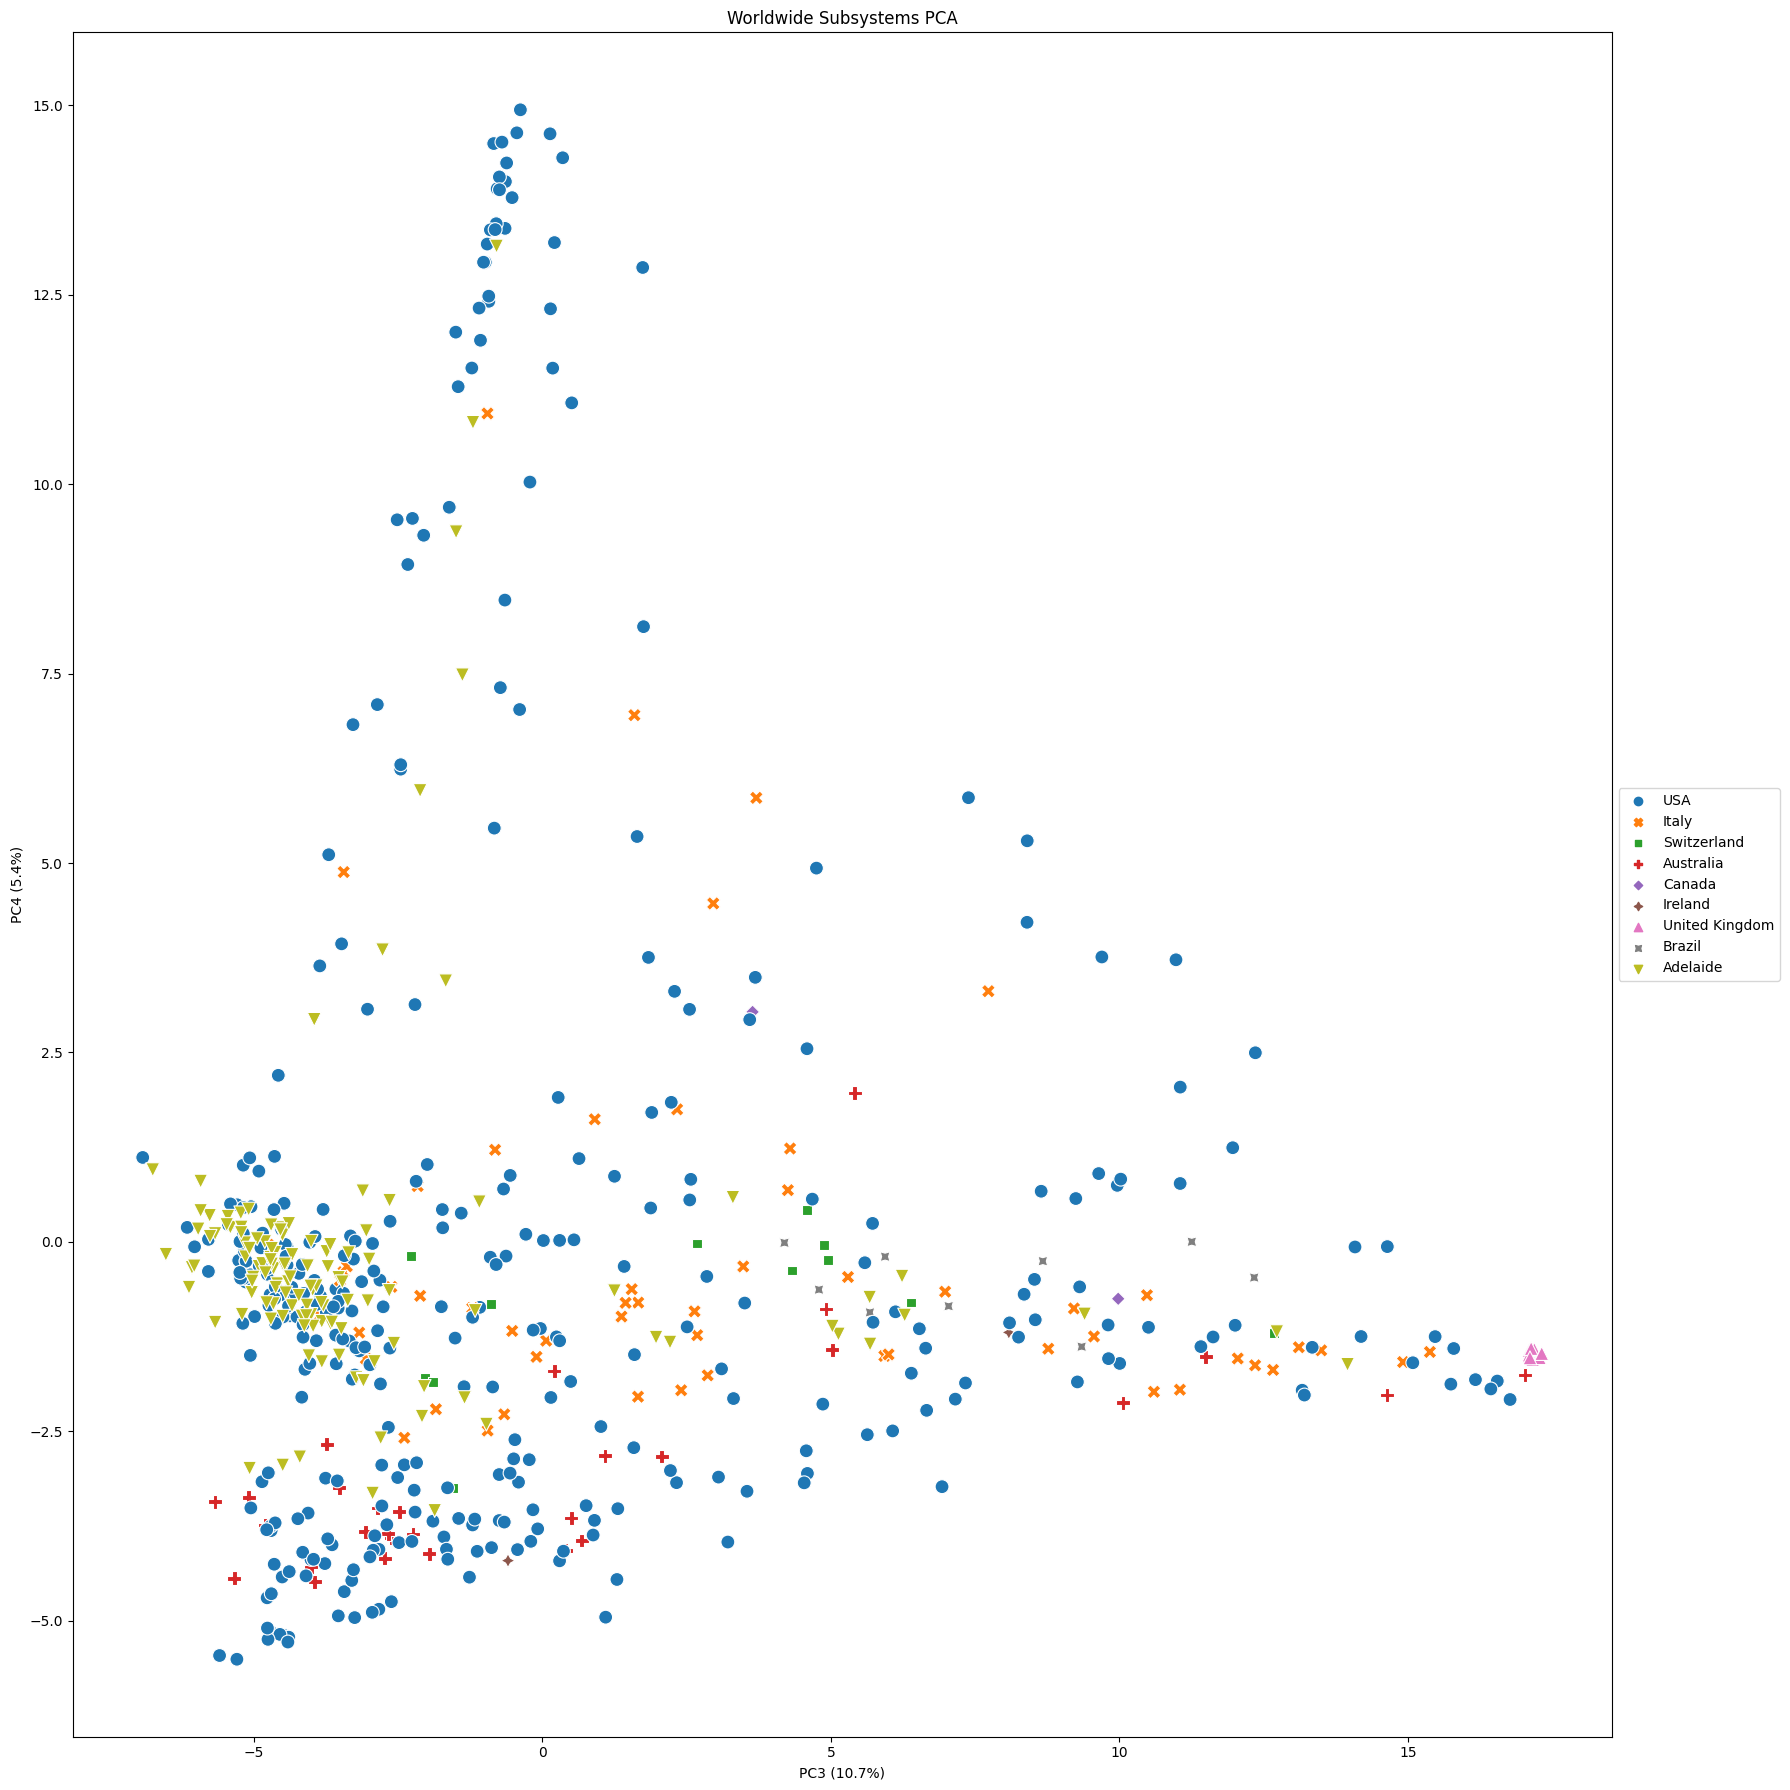

In [14]:
fig, ax = plt.subplots(figsize=(18, 18))
# pd.concat([df[df['label'] != 'dog'], df[df['label'] == 'dog']]).
dfat = pd.concat([pcloc[pcloc['Country'] != "Adelaide"], pcloc[pcloc['Country'] == "Adelaide"]])
sns.scatterplot(x="PC1", y="PC2", hue='Country', style='Country', legend=True, data=dfat, ax=ax, s=100)
l = ax.set_xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
l = ax.set_ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.1f}%)")
t = ax.set_title(f"Worldwide Subsystems PCA")
ax.legend()
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
fig.savefig("Worldwide_ss.png")

## Loadings


In [15]:
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4'], index=df.columns)
loadings.head(3)

,PC1,PC2,PC3,PC4
Amino Acids and Derivatives;,-0.103517,-0.107579,-0.082092,0.106830
"Amino Acids and Derivatives; Alanine, serine, and glycine",0.134093,0.038651,-0.098055,-0.013156
"Amino Acids and Derivatives; Arginine; urea cycle, creatine, polyamines",0.120180,0.057116,-0.035910,0.101326


In [21]:
for i, l in ldf.iterrows():
    print(f"{i}\t{l.PC1}")

Membrane Transport; Protein secretion system, Type VI	0.1579875921790256
Miscellaneous; Betaine, crotonobetaine, L-carnitine (trimethyl ammonium compounds)	0.15576010961056688
Motility and Chemotaxis; 	0.1547176636142215
Fatty Acids, Lipids, and Isoprenoids; Unsaturated fatty acids	0.1486400878774496
Membrane Transport; Protein secretion system, Type III	0.14820932856450128
Motility and Chemotaxis; Flagellum	0.14793471163372596
Respiration; 	0.14786640994783354
Membrane Transport; Multidrug efflux systems	0.14719174839398713
RNA Processing; RNA processing and modification	-0.1469168653760454
DNA Processing; DNA uptake, competence	-0.14533675977180738


For PC1, maximum for loading is 0.1579875921790256 and maximum for PCA is 17.320451527803833
For PC2, maximum for loading is 0.05875013574530493 and maximum for PCA is 14.942308249776001


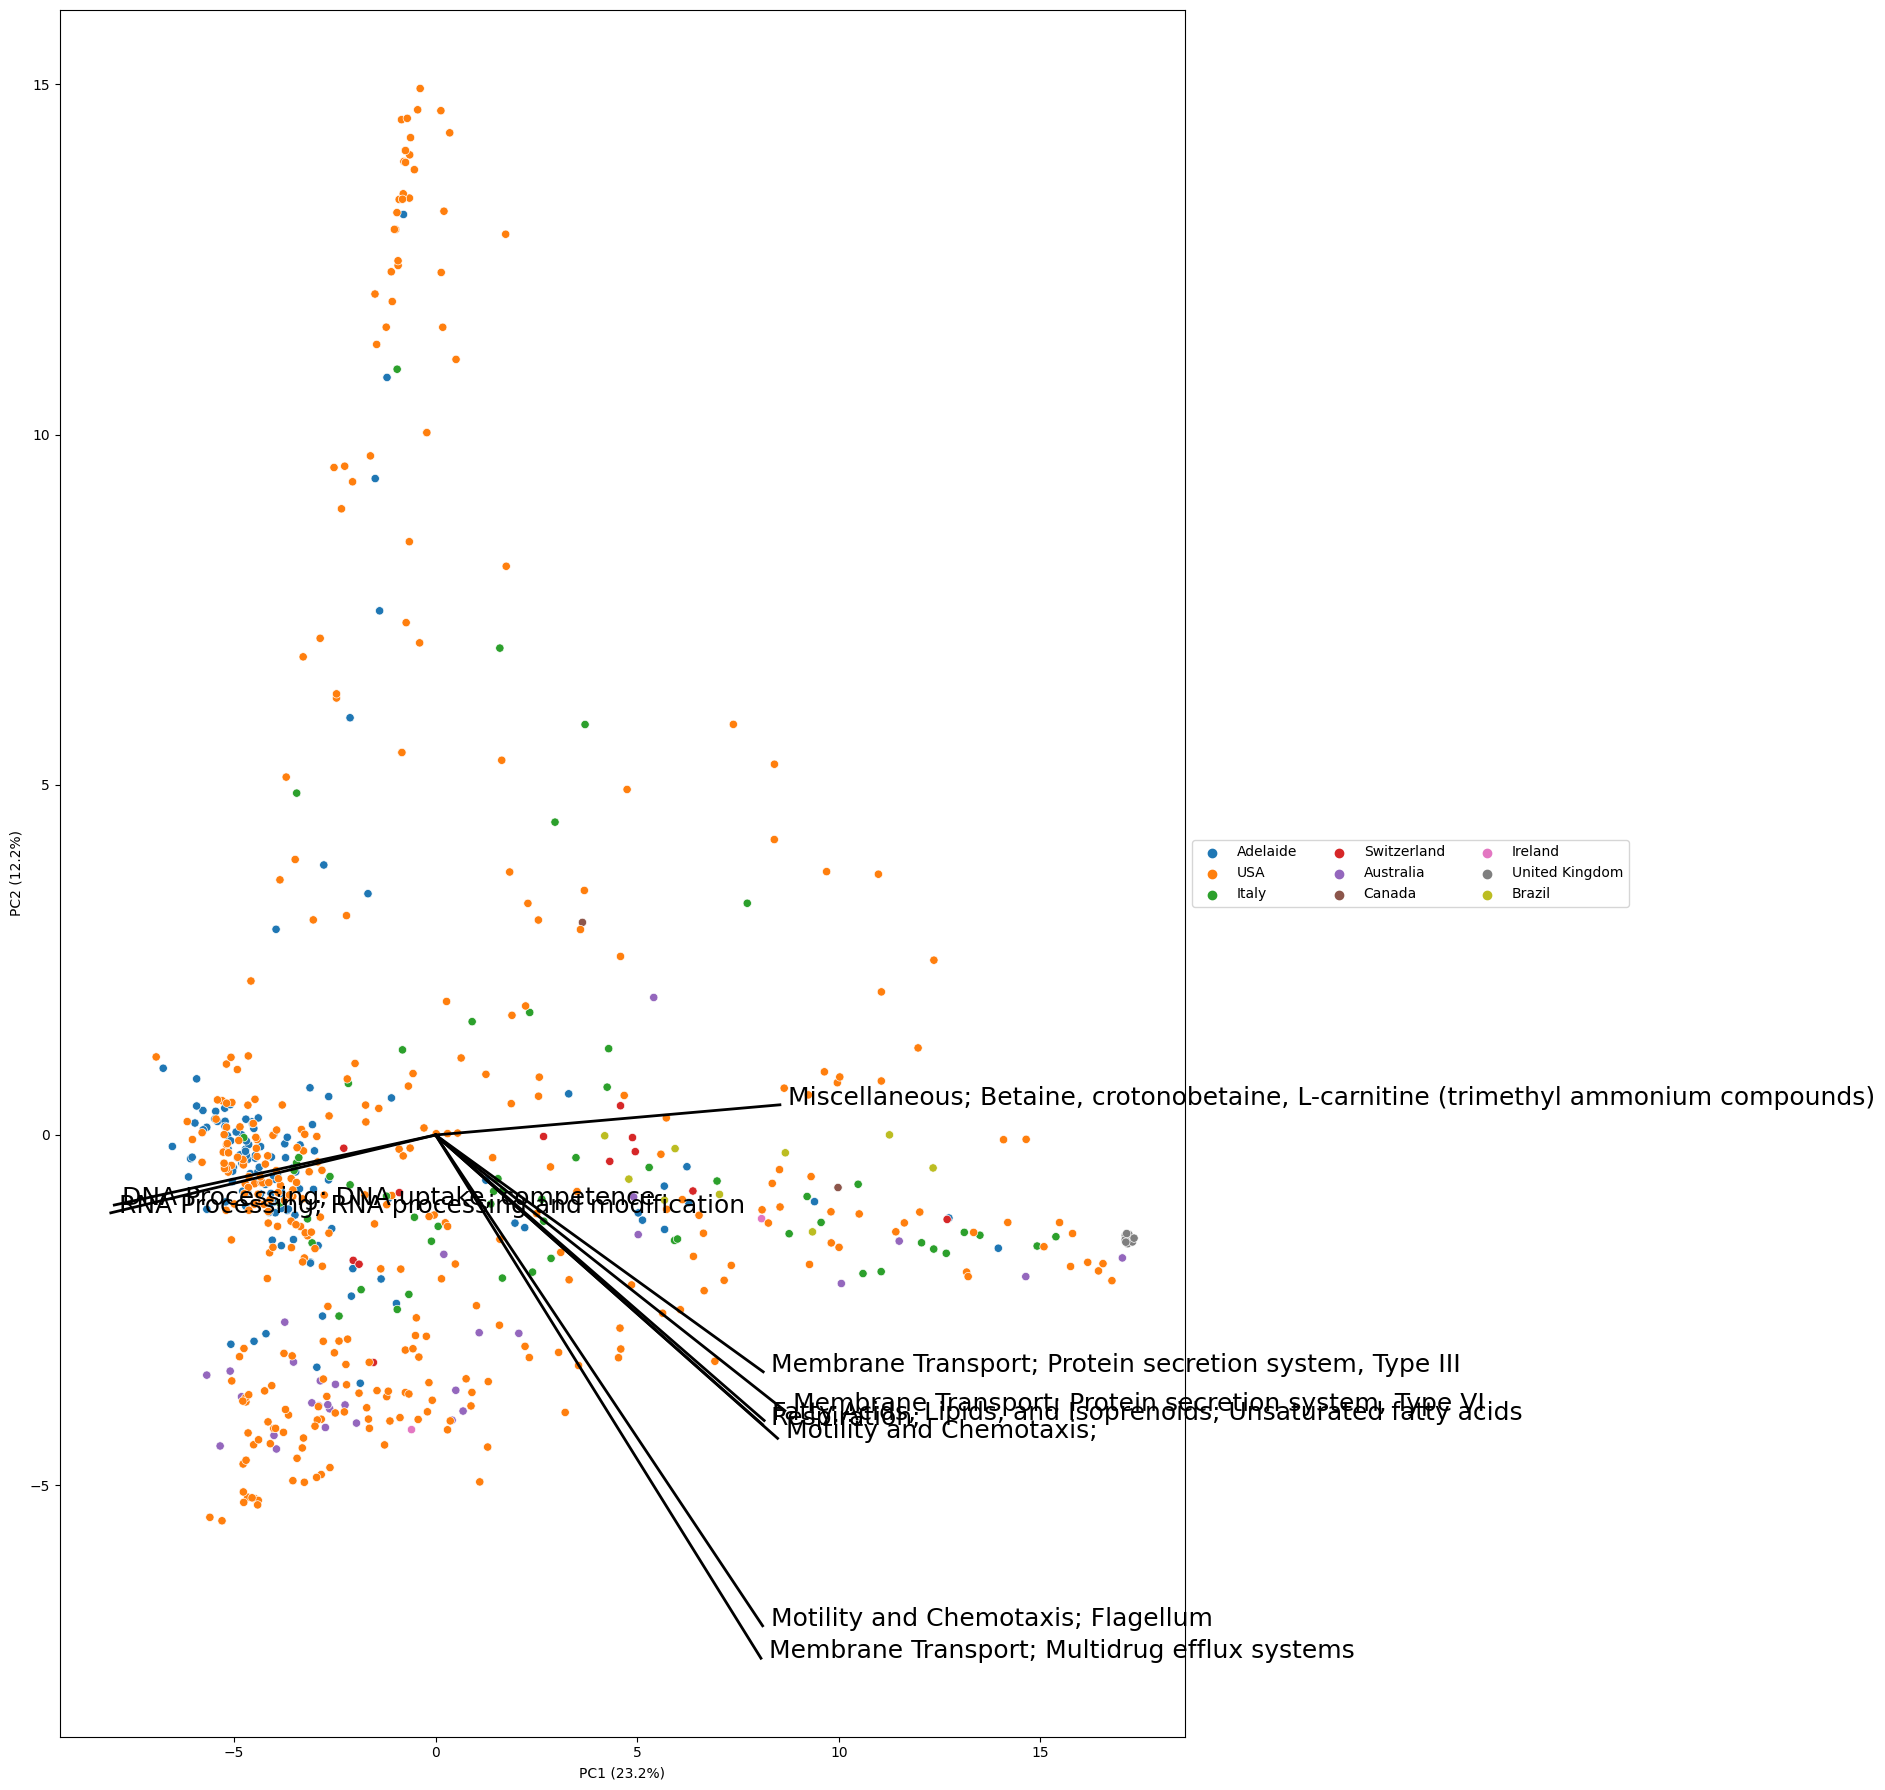

In [31]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC1", y="PC2", hue='Country', legend=True, data=pcloc, ax=ax)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=3)
l = ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
l = ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
# get the 5 largest loadings
ldf = loadings.loc[loadings.abs().nlargest(10, ['PC1', 'PC2']).index]
# get the maximum values for x and y for the loadings and the PCA
mlx = max(abs(ldf.PC1))
mly = max(abs(ldf.PC2))
mpx = max(abs(pct_df.PC1))
mpy = max(abs(pct_df.PC2))
print(f"For PC1, maximum for loading is {mlx} and maximum for PCA is {mpx}")
print(f"For PC2, maximum for loading is {mly} and maximum for PCA is {mpy}")

for i, l in ldf.iterrows():
    # scale the loadings to fit the figure
    ex = ( (l.PC1/mlx) * mpx ) / 2
    ey = ( (l.PC2/mly) * mpy ) / 2
    # add the text and the line
    plt.text(ex+0.2, ey, i, fontsize=18)
    plt.plot([0, ex ], [0, ey ], 'k-', lw=2)

plt.tight_layout()

In [33]:
df['Country']

KeyError: 'Country'

# Taxonomy

We repeat the same analysis, but with genus taxonomy

### Read the Adelaide data

In [17]:
adl = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\Adelaide\\CF_Taxonomy\\genus.tsv", delimiter="\t")
adl = adl.rename(columns={"#NAME":"Accession"})
adl = adl.set_index("Accession")
adl = adl.reindex(natsorted(adl.columns), axis=1)
adl = adl.T
# normalise the data by the row sum before we add the label
adl = adl.div(adl.sum(axis=1), axis=0)
adl['geo_loc_name_country_calc'] = "Adelaide"
adl

Accession,g__Halothece,g__Dasypyrum,g__Geofilum,g__Triplophysa,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,...,g__Marivivens,g__Penicilliopsis,g__Rehaibacterium,g__Halopiger,g__Budvicia,g__Biseptimavirus,g__Anaerotalea,g__Frankliniella,g__Peterkaempfera,geo_loc_name_country_calc
623361_20180123_S,0.0,0.0,1.871224e-05,0.0,0.0,0.000000e+00,0.000002,0.0,8.135756e-07,0.000000,...,0.000000,0.0,0.0,0.0,0.000006,0.000000,2.440727e-06,1.627151e-06,0.0,Adelaide
634207_20180510_S,0.0,0.0,7.366511e-06,0.0,0.0,4.333242e-07,0.000005,0.0,0.000000e+00,0.000003,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,1.299973e-06,8.666484e-07,0.0,Adelaide
634207_20180517_S,0.0,0.0,1.290154e-05,0.0,0.0,0.000000e+00,0.000005,0.0,0.000000e+00,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,2.276743e-06,0.000000e+00,0.0,Adelaide
639354_20171206_S,0.0,0.0,3.705914e-06,0.0,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000015,...,0.000000,0.0,0.0,0.0,0.000015,0.000007,7.411827e-06,0.000000e+00,0.0,Adelaide
642660_20180601_S,0.0,0.0,9.695324e-07,0.0,0.0,0.000000e+00,0.000002,0.0,0.000000e+00,0.000002,...,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000e+00,0.000000e+00,0.0,Adelaide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690154_20180406_S,0.0,0.0,4.824772e-06,0.0,0.0,0.000000e+00,0.000006,0.0,0.000000e+00,0.000000,...,0.000000,0.0,0.0,0.0,0.000002,0.000000,3.216515e-06,0.000000e+00,0.0,Adelaide
1723809_20180227_S,0.0,0.0,4.902915e-06,0.0,0.0,0.000000e+00,0.000002,0.0,9.805830e-07,0.000001,...,0.000005,0.0,0.0,0.0,0.000010,0.000000,9.805830e-07,9.805830e-07,0.0,Adelaide
1834617_20180501_S,0.0,0.0,5.850432e-06,0.0,0.0,0.000000e+00,0.000007,0.0,0.000000e+00,0.000001,...,0.000000,0.0,0.0,0.0,0.000000,0.000040,2.080154e-05,0.000000e+00,0.0,Adelaide
1845116_20180403_S,0.0,0.0,1.677878e-05,0.0,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000002,...,0.000001,0.0,0.0,0.0,0.000014,0.000000,9.869871e-07,8.389390e-06,0.0,Adelaide


### Read the worldwide data

In [18]:
wlt = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\mmseqs_taxonomy\\genus.tsv", delimiter="\t")
wlt = wlt.rename(columns={"#NAME":"Accession"})
wlt = wlt.set_index('Accession')
wlt = wlt.reindex(natsorted(wlt.columns), axis=1)
wlt = wlt.T
# normalise the data by the row sum 
wlt = wlt.div(wlt.sum(axis=1), axis=0)
wlt

Accession,g__Morella,g__Neofusicoccum,g__Phoenicibacter,g__Epsilonretrovirus,g__Suspvirus,g__Halopiger,g__Halosegnis,g__Lacerta,g__Dickeya,g__Exilisciurus,...,g__Ruegeria,g__Telluria,g__Votkovvirus,g__Python,g__Marinicella,g__Trifolium,g__Candidatus Ichthyocystis,g__Balaeniceps,g__Dragolirvirus,g__Cytomegalovirus
SRR1177122,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,8.719047e-05,0.0,0.000000e+00,0.0,0.0
SRR1180012,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,3.929852e-05,0.0,0.000000e+00,0.0,0.0
SRR1180013,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.091203e-04,0.0,0.000000e+00,0.0,0.0
SRR3284698,0.000000e+00,0.000000e+00,0.000000,0.000002,0.000000e+00,0.000000,0.0,0.000004,4.784334e-06,0.0,...,0.000000e+00,0.0,0.000000e+00,1.594778e-05,0.000000e+00,4.624856e-04,0.0,7.973890e-07,0.0,0.0
SRR3284701,0.000000e+00,0.000000e+00,0.000000,0.000008,0.000000e+00,0.000000,0.0,0.000005,8.493132e-07,0.0,...,8.493132e-07,0.0,0.000000e+00,1.104107e-05,8.493132e-07,5.146838e-04,0.0,0.000000e+00,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.000000e+00,0.000000e+00,0.000052,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.484000e-05,0.0,...,2.574285e-06,0.0,0.000000e+00,0.000000e+00,9.085712e-07,0.000000e+00,0.0,0.000000e+00,0.0,0.0
SRR24155134,0.000000e+00,0.000000e+00,0.000079,0.000000,2.076798e-07,0.000000,0.0,0.000000,1.526447e-05,0.0,...,2.076798e-07,0.0,2.076798e-07,1.038399e-07,0.000000e+00,1.142239e-06,0.0,0.000000e+00,0.0,0.0
SRR24155135,1.268853e-07,0.000000e+00,0.000005,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.268853e-07,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0
SRR24155136,0.000000e+00,0.000000e+00,0.000002,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.105983e-05,0.0,...,1.286027e-07,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.286027e-07,0.0,0.000000e+00,0.0,0.0


In [19]:
six = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\16S.tsv", delimiter="\t")
sr = six[six["Aligned 1 time"] > 1]
wlt = wlt[~wlt.index.isin(sr['Run'])]
wlt

Accession,g__Morella,g__Neofusicoccum,g__Phoenicibacter,g__Epsilonretrovirus,g__Suspvirus,g__Halopiger,g__Halosegnis,g__Lacerta,g__Dickeya,g__Exilisciurus,...,g__Ruegeria,g__Telluria,g__Votkovvirus,g__Python,g__Marinicella,g__Trifolium,g__Candidatus Ichthyocystis,g__Balaeniceps,g__Dragolirvirus,g__Cytomegalovirus
SRR1177122,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,8.719047e-05,0.0,0.000000e+00,0.0,0.0
SRR1180012,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,3.929852e-05,0.0,0.000000e+00,0.0,0.0
SRR1180013,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000,0.000000e+00,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.091203e-04,0.0,0.000000e+00,0.0,0.0
SRR3284698,0.000000e+00,0.000000e+00,0.000000,0.000002,0.000000e+00,0.000000,0.0,0.000004,4.784334e-06,0.0,...,0.000000e+00,0.0,0.000000e+00,1.594778e-05,0.000000e+00,4.624856e-04,0.0,7.973890e-07,0.0,0.0
SRR3284701,0.000000e+00,0.000000e+00,0.000000,0.000008,0.000000e+00,0.000000,0.0,0.000005,8.493132e-07,0.0,...,8.493132e-07,0.0,0.000000e+00,1.104107e-05,8.493132e-07,5.146838e-04,0.0,0.000000e+00,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.000000e+00,0.000000e+00,0.000052,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.484000e-05,0.0,...,2.574285e-06,0.0,0.000000e+00,0.000000e+00,9.085712e-07,0.000000e+00,0.0,0.000000e+00,0.0,0.0
SRR24155134,0.000000e+00,0.000000e+00,0.000079,0.000000,2.076798e-07,0.000000,0.0,0.000000,1.526447e-05,0.0,...,2.076798e-07,0.0,2.076798e-07,1.038399e-07,0.000000e+00,1.142239e-06,0.0,0.000000e+00,0.0,0.0
SRR24155135,1.268853e-07,0.000000e+00,0.000005,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.268853e-07,0.0,...,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0
SRR24155136,0.000000e+00,0.000000e+00,0.000002,0.000000,0.000000e+00,0.000000,0.0,0.000000,1.105983e-05,0.0,...,1.286027e-07,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.286027e-07,0.0,0.000000e+00,0.0,0.0


## Add the metadata

In [20]:
wmd = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\bq-results-20230813-093918-1691921491006.tsv", delimiter="\t")
wma = wmd[['Accession', 'geo_loc_name_country_calc']]
wma = wma.set_index("Accession")
wldj = wlt.join(wma,  how='inner')
comb = pd.concat([adl, wldj], axis=0)
comb

,g__Halothece,g__Dasypyrum,g__Geofilum,g__Triplophysa,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,...,g__Esteya,g__Sripuvirus,g__Scapholeberis,g__Hippolais,g__Sphaerimonospora,g__Telluria,g__Votkovvirus,g__Python,g__Balaeniceps,g__Dragolirvirus
623361_20180123_S,0.0,0.0,1.871224e-05,0.0,0.0,0.000000e+00,1.627151e-06,0.000000e+00,8.135756e-07,0.000000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
634207_20180510_S,0.0,0.0,7.366511e-06,0.0,0.0,4.333242e-07,5.199890e-06,0.000000e+00,0.000000e+00,2.599945e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
634207_20180517_S,0.0,0.0,1.290154e-05,0.0,0.0,0.000000e+00,5.312399e-06,0.000000e+00,0.000000e+00,0.000000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
639354_20171206_S,0.0,0.0,3.705914e-06,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.482365e-05,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
642660_20180601_S,0.0,0.0,9.695324e-07,0.0,0.0,0.000000e+00,1.939065e-06,0.000000e+00,0.000000e+00,1.939065e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.0,0.0,1.041828e-04,0.0,0.0,4.542856e-07,0.000000e+00,3.028571e-07,0.000000e+00,1.060000e-06,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0
SRR24155134,0.0,0.0,0.000000e+00,0.0,0.0,9.034073e-06,9.864792e-06,0.000000e+00,0.000000e+00,5.191996e-07,...,0.0,0.0,0.0,0.0,0.0,0.0,2.076798e-07,1.038399e-07,0.0,0.0
SRR24155135,0.0,0.0,6.344266e-08,0.0,0.0,6.344266e-08,8.247546e-07,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0
SRR24155136,0.0,0.0,0.000000e+00,0.0,0.0,2.572054e-07,3.858081e-07,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0


## Reset the metadata

In [21]:
locs = comb[['geo_loc_name_country_calc']]
locs = locs.rename(columns={"geo_loc_name_country_calc": "Country"})
df = comb.drop(['geo_loc_name_country_calc'], axis=1)
df = df.dropna(axis=1)
df

,g__Halothece,g__Dasypyrum,g__Geofilum,g__Triplophysa,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,...,g__Mangrovicoccus,g__Marivivens,g__Penicilliopsis,g__Rehaibacterium,g__Halopiger,g__Budvicia,g__Biseptimavirus,g__Anaerotalea,g__Frankliniella,g__Peterkaempfera
623361_20180123_S,0.0,0.0,1.871224e-05,0.0,0.0,0.000000e+00,1.627151e-06,0.000000e+00,8.135756e-07,0.000000e+00,...,0.000000e+00,0.0,0.000000e+00,0.0,0.000000,5.695030e-06,0.000000e+00,0.000002,1.627151e-06,0.0
634207_20180510_S,0.0,0.0,7.366511e-06,0.0,0.0,4.333242e-07,5.199890e-06,0.000000e+00,0.000000e+00,2.599945e-06,...,8.666484e-07,0.0,0.000000e+00,0.0,0.000000,0.000000e+00,0.000000e+00,0.000001,8.666484e-07,0.0
634207_20180517_S,0.0,0.0,1.290154e-05,0.0,0.0,0.000000e+00,5.312399e-06,0.000000e+00,0.000000e+00,0.000000e+00,...,7.589142e-07,0.0,0.000000e+00,0.0,0.000000,0.000000e+00,0.000000e+00,0.000002,0.000000e+00,0.0
639354_20171206_S,0.0,0.0,3.705914e-06,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.482365e-05,...,0.000000e+00,0.0,0.000000e+00,0.0,0.000000,1.482365e-05,7.411827e-06,0.000007,0.000000e+00,0.0
642660_20180601_S,0.0,0.0,9.695324e-07,0.0,0.0,0.000000e+00,1.939065e-06,0.000000e+00,0.000000e+00,1.939065e-06,...,0.000000e+00,0.0,0.000000e+00,0.0,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.0,0.0,1.041828e-04,0.0,0.0,4.542856e-07,0.000000e+00,3.028571e-07,0.000000e+00,1.060000e-06,...,3.028571e-07,0.0,0.000000e+00,0.0,0.000000,1.302285e-05,0.000000e+00,0.000022,0.000000e+00,0.0
SRR24155134,0.0,0.0,0.000000e+00,0.0,0.0,9.034073e-06,9.864792e-06,0.000000e+00,0.000000e+00,5.191996e-07,...,0.000000e+00,0.0,1.038399e-07,0.0,0.000000,1.100703e-05,0.000000e+00,0.000012,0.000000e+00,0.0
SRR24155135,0.0,0.0,6.344266e-08,0.0,0.0,6.344266e-08,8.247546e-07,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.0,6.344266e-08,0.0,0.000000,8.881973e-07,0.000000e+00,0.000005,0.000000e+00,0.0
SRR24155136,0.0,0.0,0.000000e+00,0.0,0.0,2.572054e-07,3.858081e-07,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.0,0.000000e+00,0.0,0.000000,3.073605e-05,0.000000e+00,0.000017,0.000000e+00,0.0


## Start the PCA

In [22]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
pca = PCA(n_components=4)
pca.fit(df_scaled)
dft_pca = pca.transform(df_scaled)
zipped = list(zip(dft_pca[:,0],
                  dft_pca[:,1],
                  dft_pca[:,2],
                  dft_pca[:,3],
                  list(df.index),
                 ))
pct_df = pd.DataFrame(zipped, columns=['PC1', 'PC2', 'PC3', 'PC4', "Accession"])
pcloc = pct_df.set_index("Accession").join(locs, how="inner")
pcloc = pcloc[pcloc['Country'] != 'uncalculated']
pcloc

,PC1,PC2,PC3,PC4,Country
623361_20180123_S,-4.623466,-5.848245,-2.407736,-2.864882,Adelaide
634207_20180510_S,-8.594295,8.665920,-2.384597,-1.744950,Adelaide
634207_20180517_S,-5.895867,-1.545443,-2.876005,-3.831309,Adelaide
639354_20171206_S,-3.490873,-6.825771,-0.155360,-2.800543,Adelaide
642660_20180601_S,-1.816615,-7.020465,-5.931498,-2.017650,Adelaide
...,...,...,...,...,...
SRR24155132,-12.104862,19.980090,-0.420704,-0.976154,USA
SRR24155134,-10.797615,14.883392,-3.367628,-1.941546,USA
SRR24155135,-2.891206,-5.331630,-6.085072,-3.782036,USA
SRR24155136,-6.000711,2.320115,-4.321360,-3.753080,USA


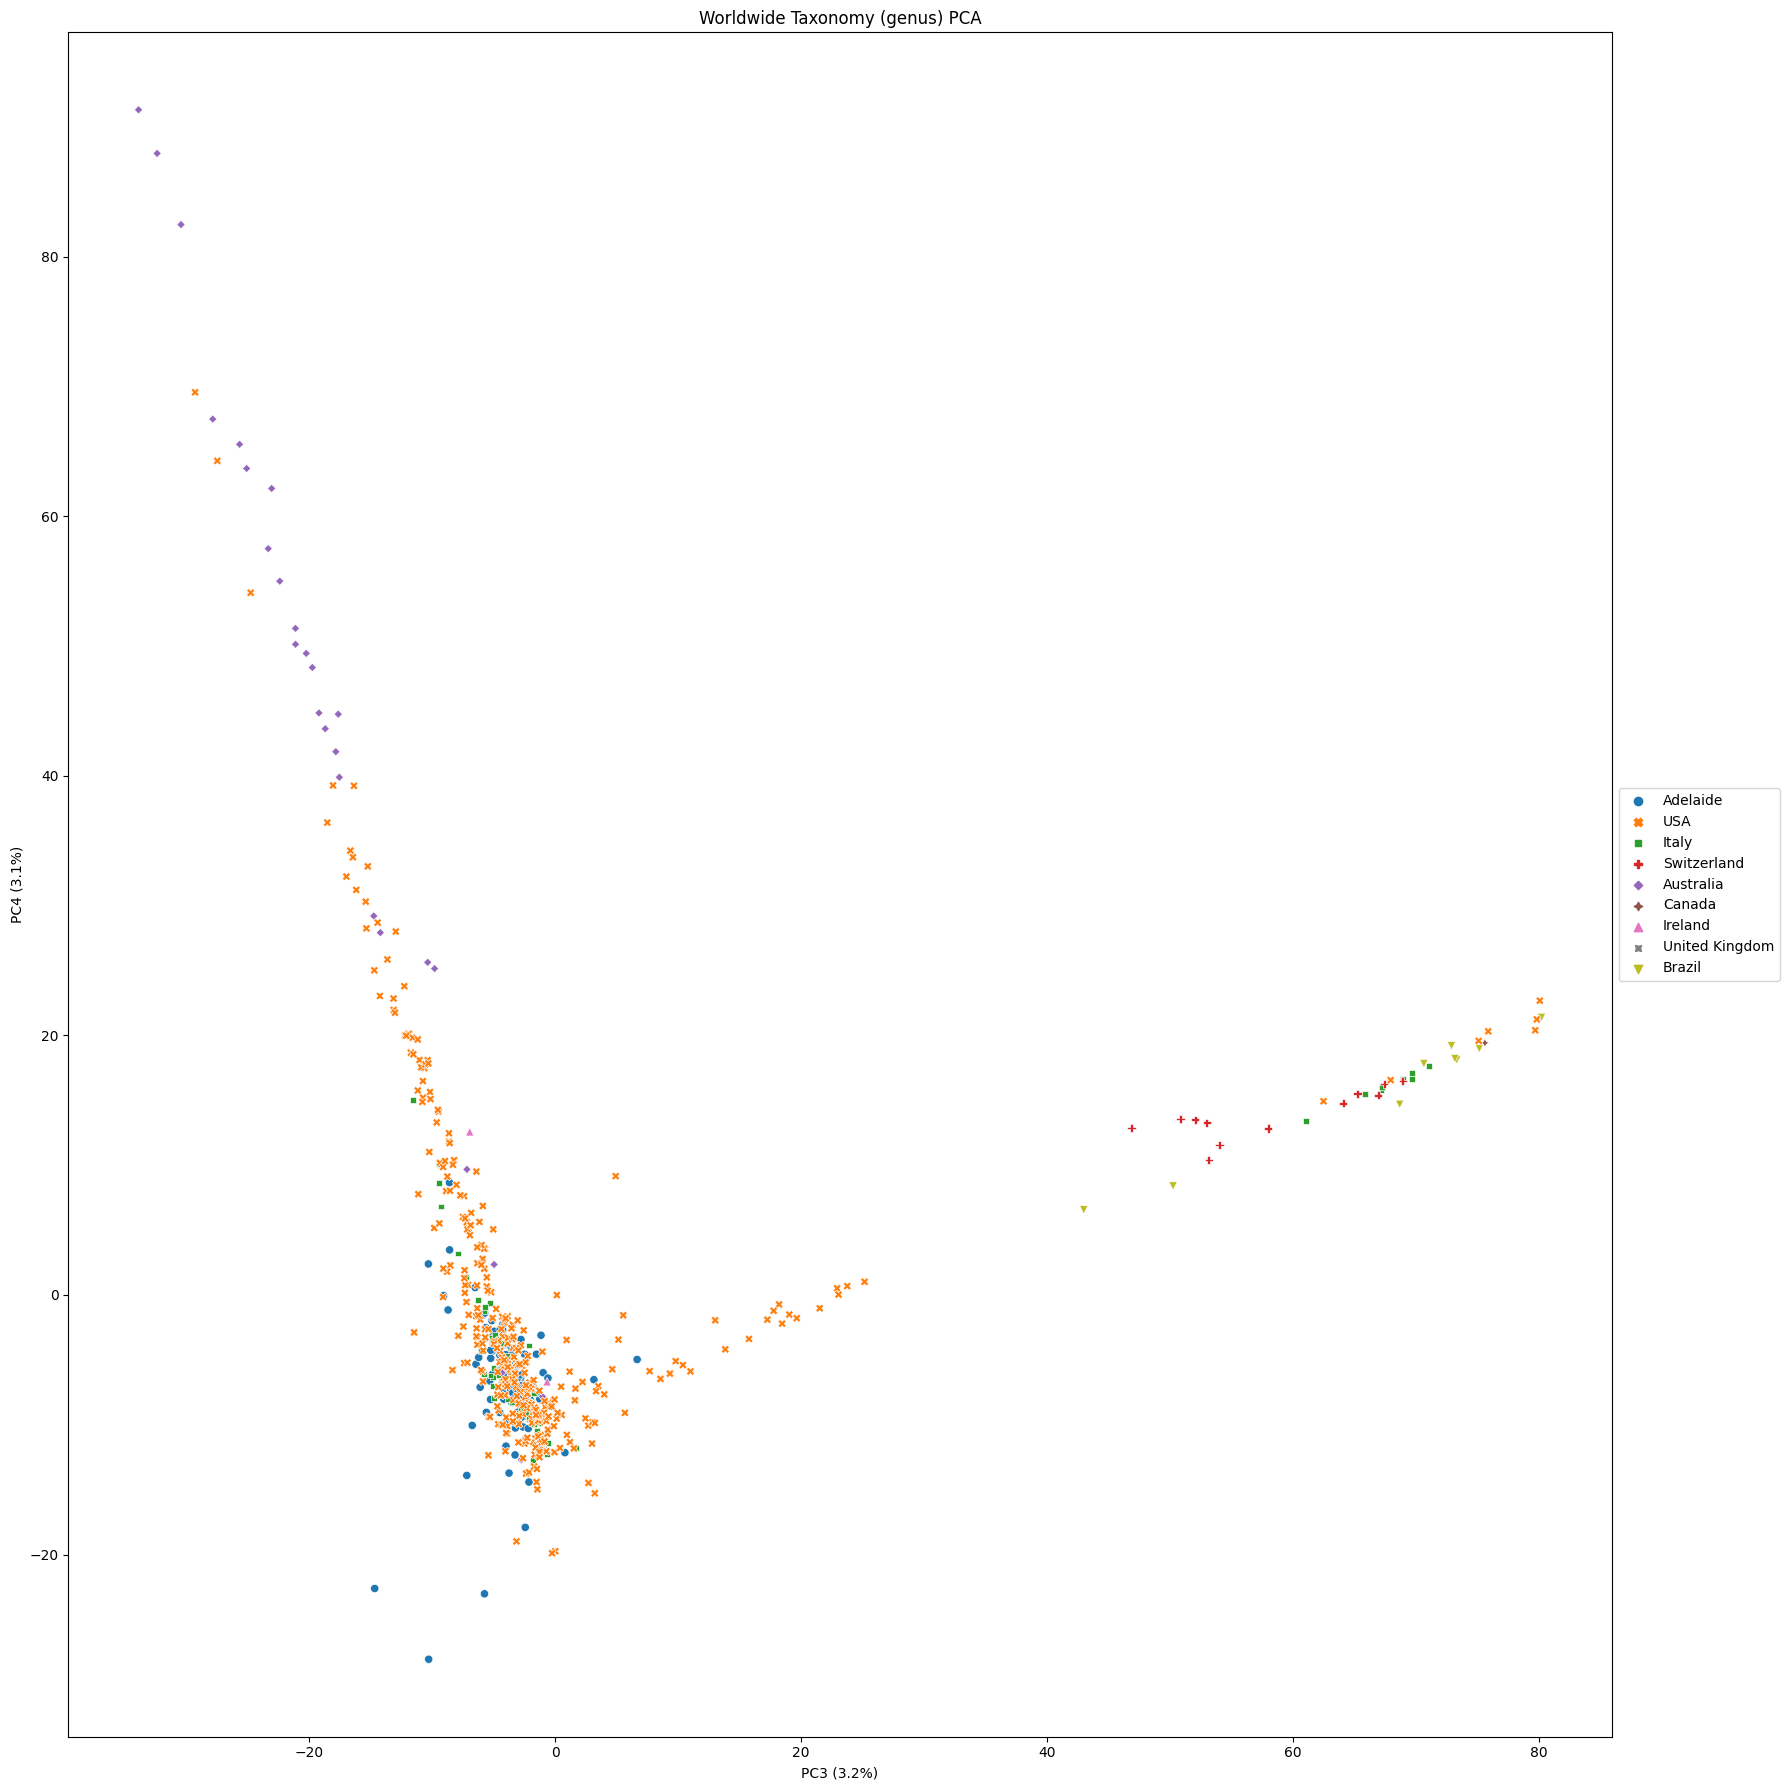

In [23]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC1", y="PC2", hue='Country', style='Country', legend=True, data=pcloc, ax=ax)
l = ax.set_xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
l = ax.set_ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.1f}%)")
t = ax.set_title(f"Worldwide Taxonomy (genus) PCA")
ax.legend()
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()


In [24]:
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4'], index=df.columns)
loadings.head(3)

,PC1,PC2,PC3,PC4
g__Halothece,0.001022,-0.001119,-0.000365,-0.000661
g__Dasypyrum,-0.000185,-0.000655,0.002092,-0.000276
g__Geofilum,-0.012826,0.027155,0.004218,0.011725


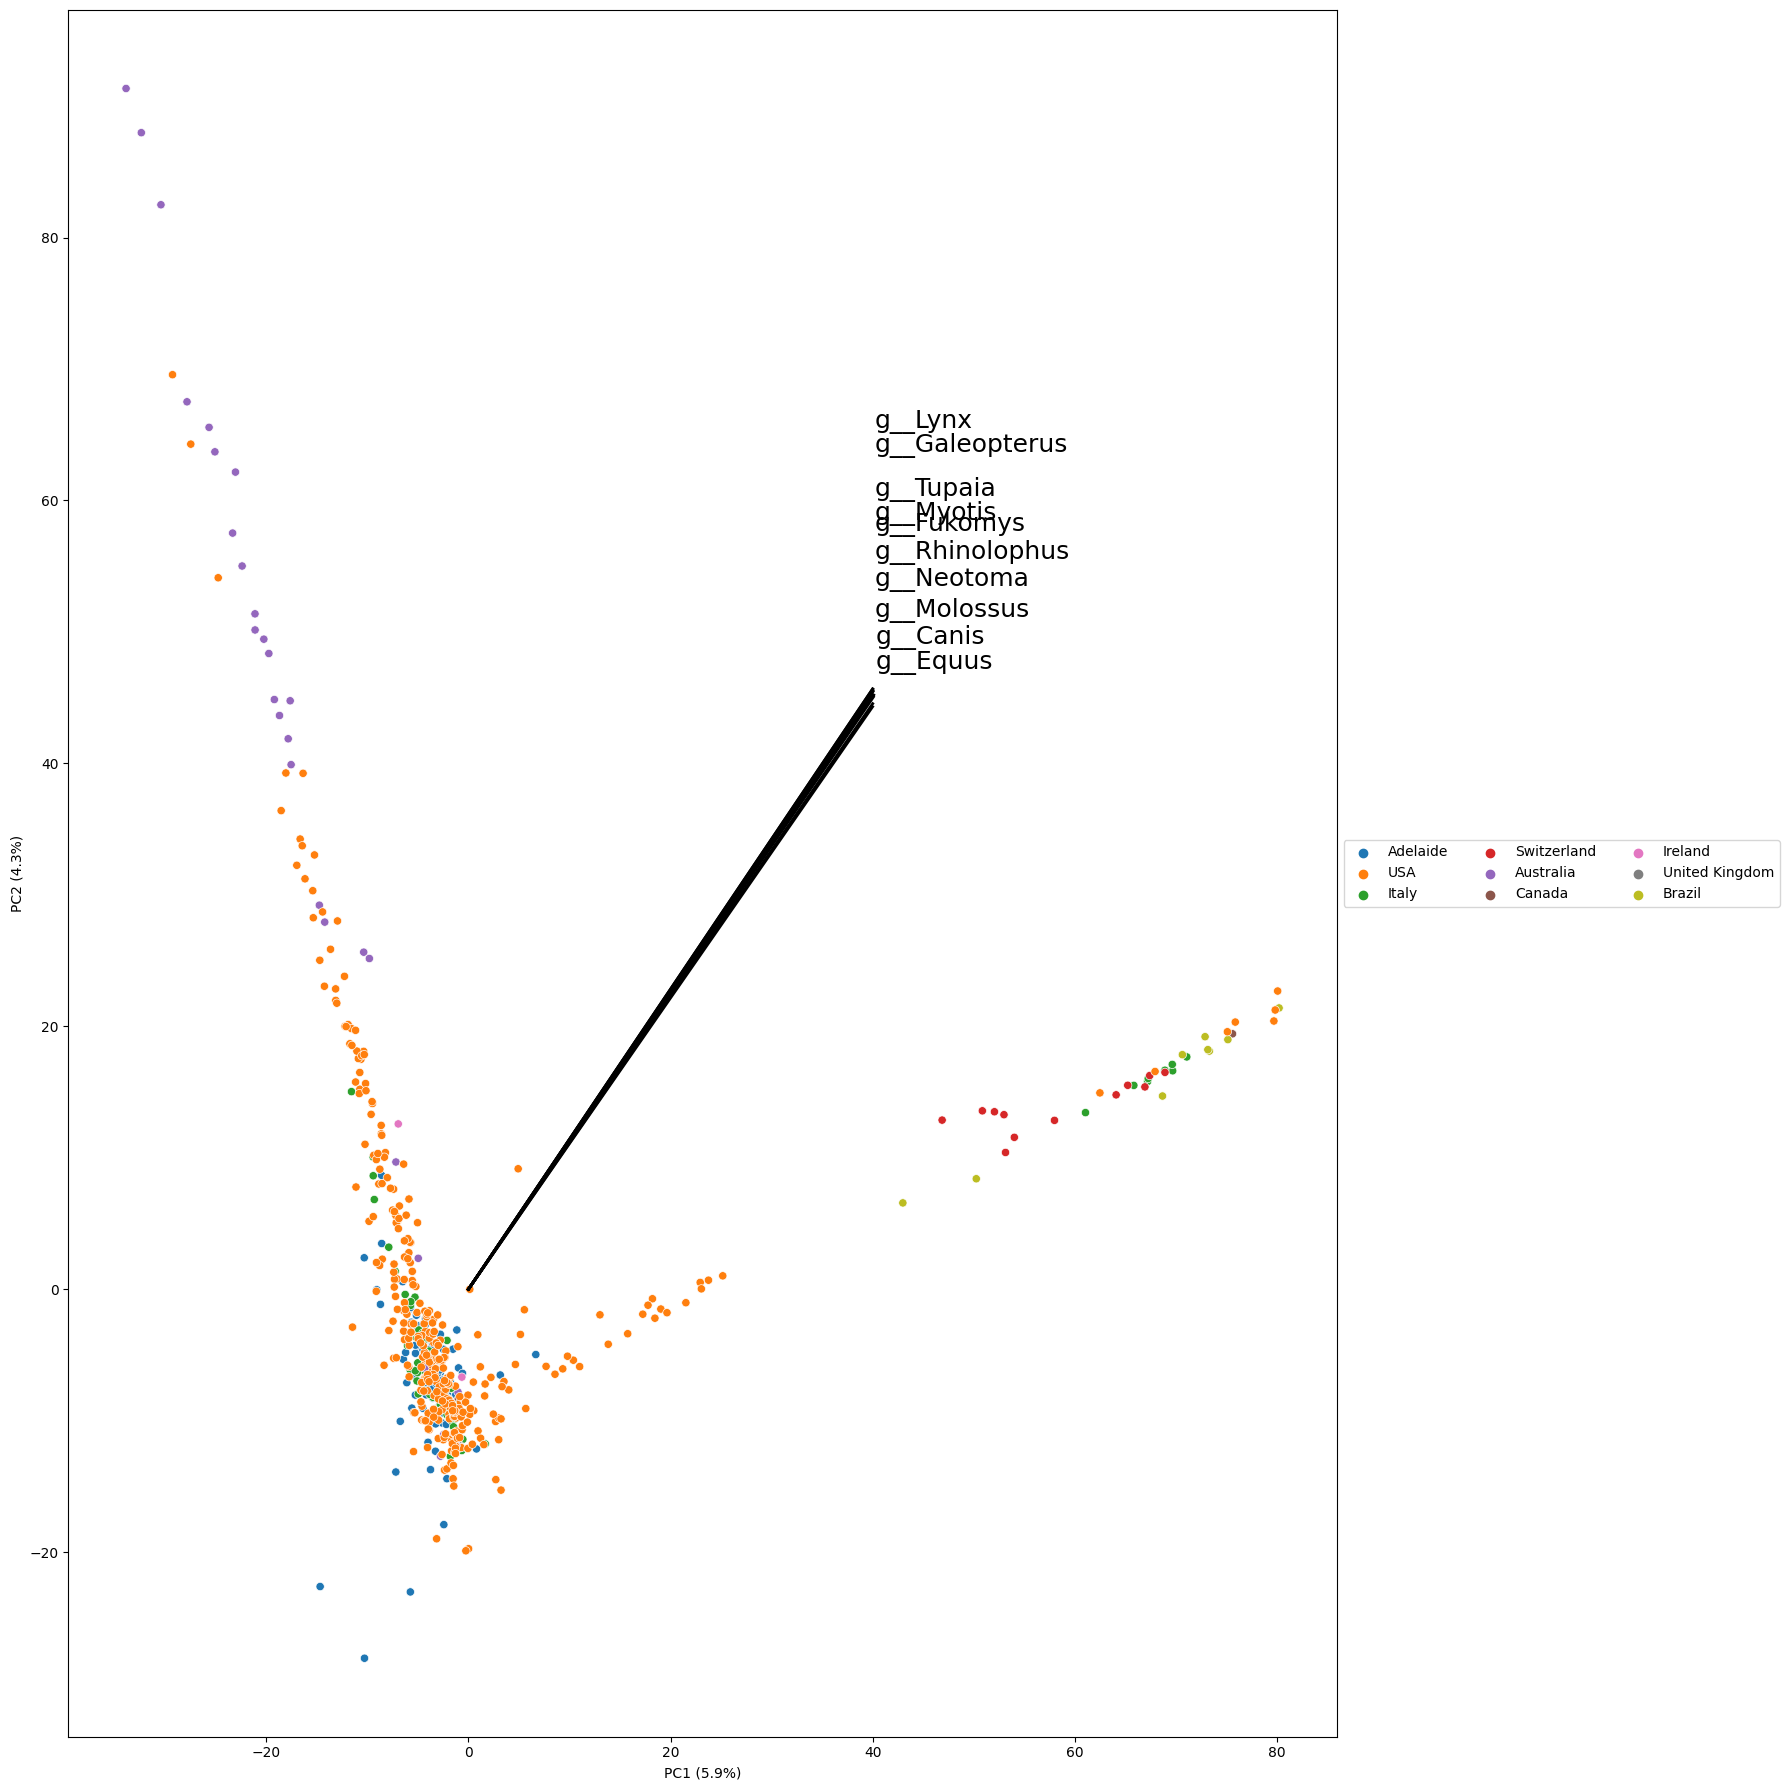

In [25]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC1", y="PC2", hue='Country', legend=True, data=pcloc, ax=ax)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=3)
l = ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
l = ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
# get the 5 largest loadings
ldf = loadings.loc[loadings.abs().nlargest(10, ['PC1', 'PC2']).index]
# get the maximum values for x and y for the loadings and the PCA
mlx = max(ldf.PC1)
mly = max(ldf.PC2)
mpx = max(pct_df.PC1)
mpy = max(pct_df.PC2)

c = 0
for i, l in ldf.iterrows():
    c+=2
    # scale the loadings to fit the figure
    ex = ( l.PC1 * (mpx/mlx) ) / 2
    ey = ( l.PC2 * (mpy/mly) ) / 2
    # add the text and the line
    plt.text(ex+0.2, ey+c, i, fontsize=18)
    plt.plot([0, ex ], [0, ey ], 'k-', lw=2)

plt.tight_layout()
fig.savefig("Worldwide_taxonomy_genus.png")

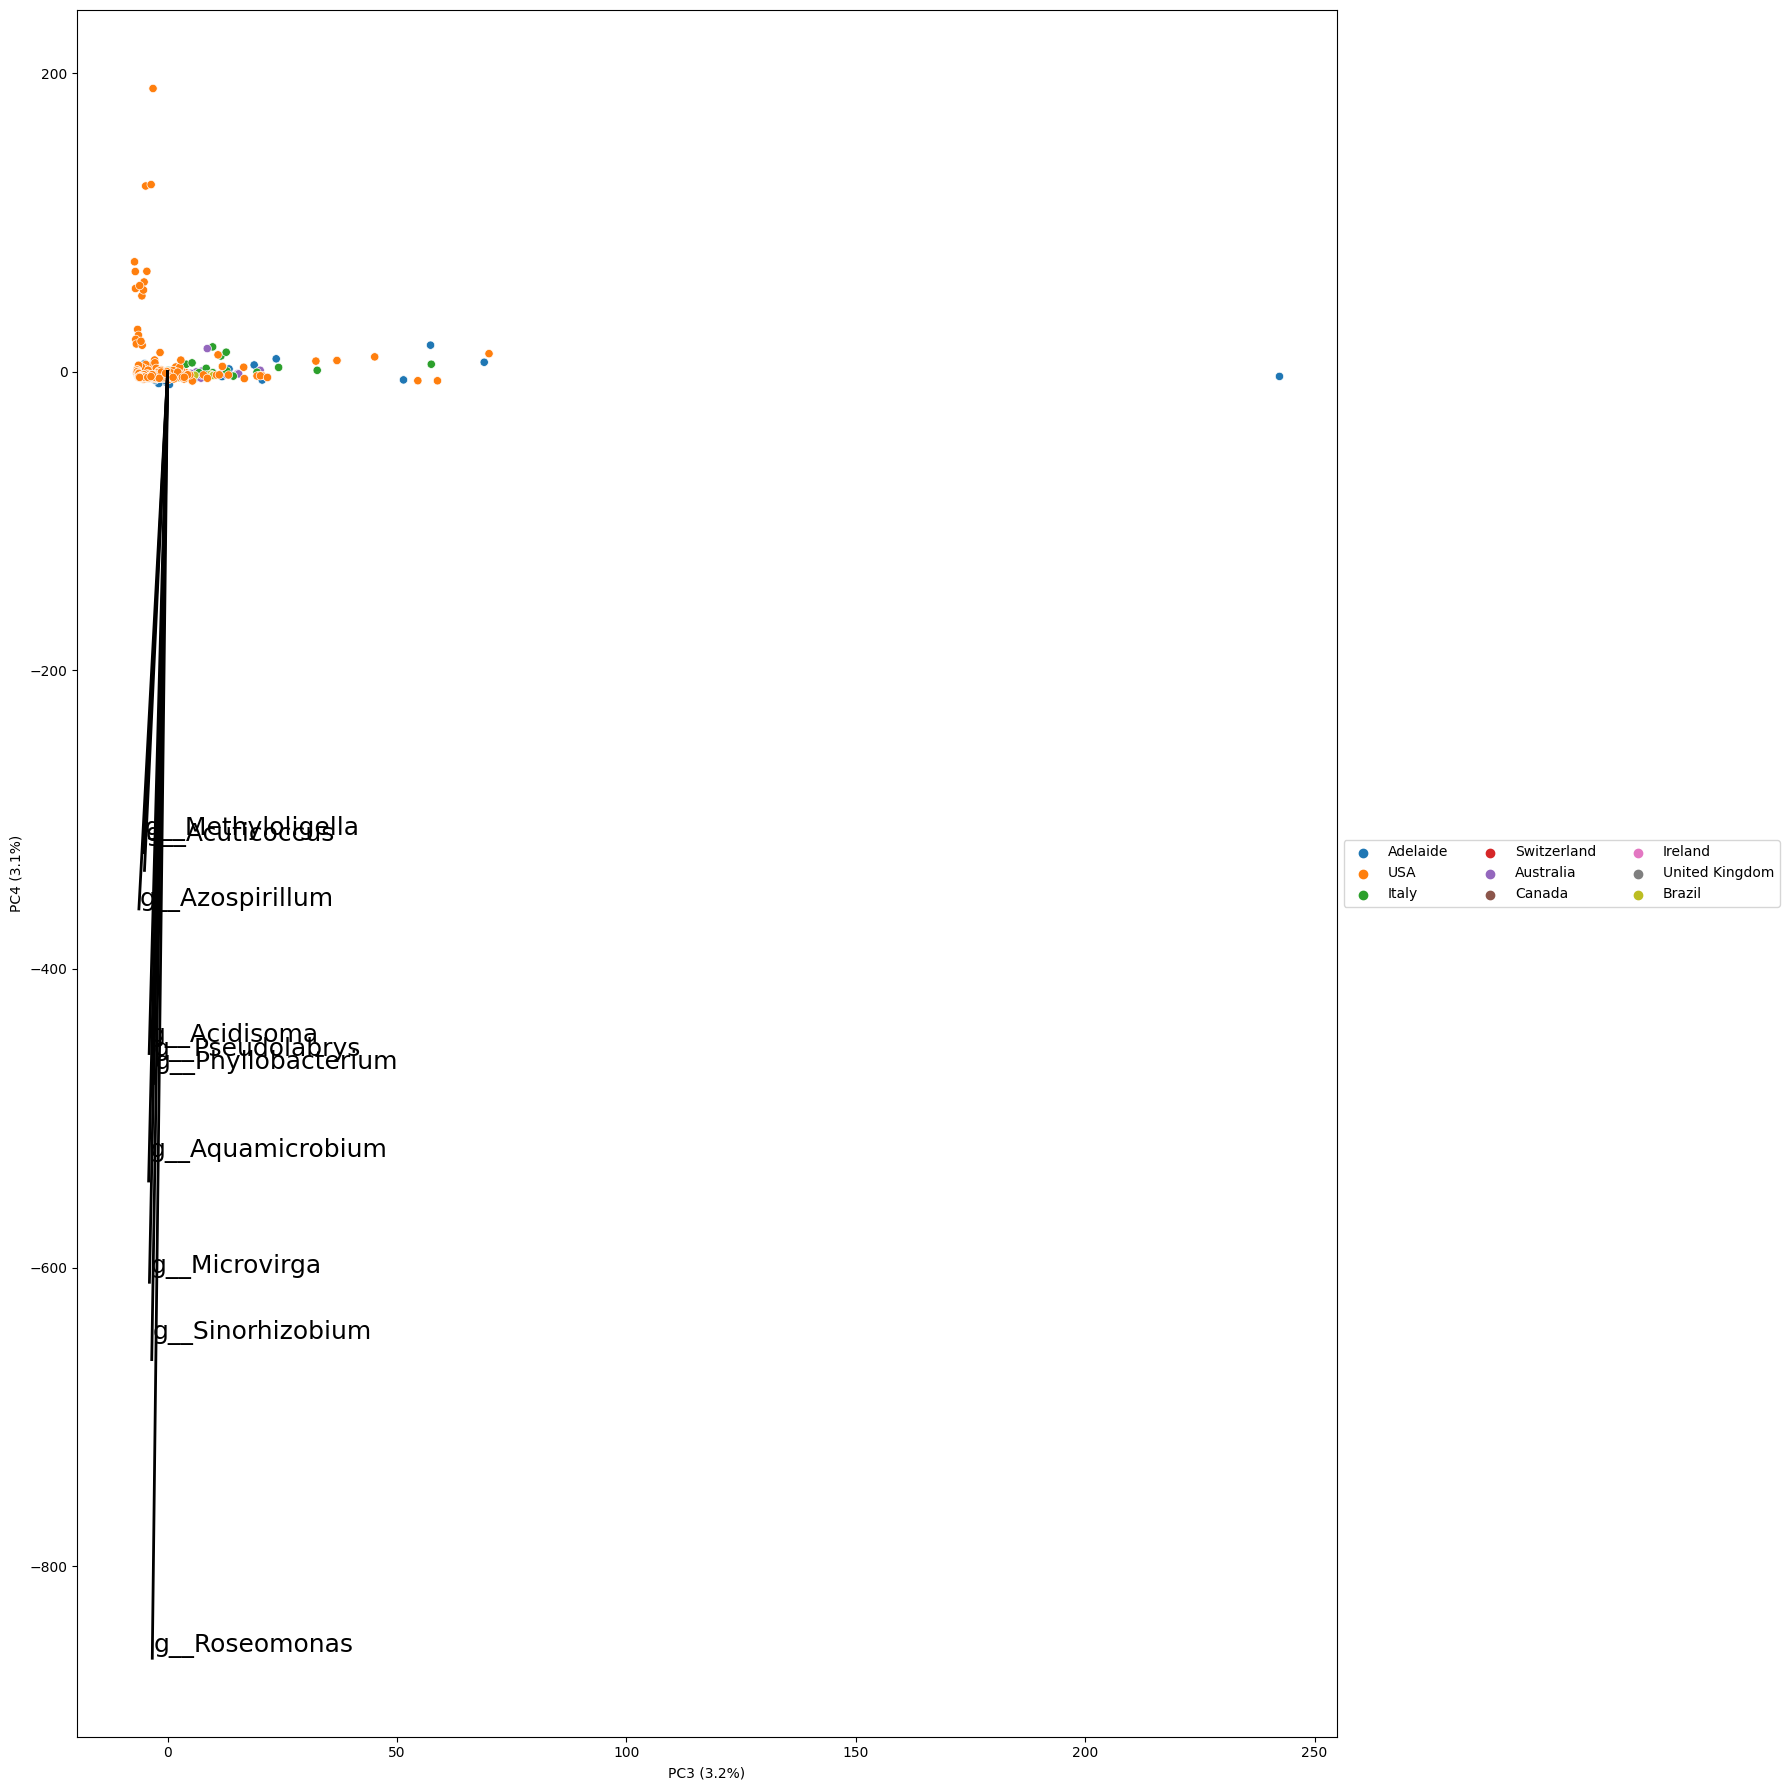

In [26]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC3", y="PC4", hue='Country', legend=True, data=pcloc, ax=ax)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=3)
l = ax.set_xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
l = ax.set_ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.1f}%)")
# get the 5 largest loadings
ldf = loadings.loc[loadings.abs().nlargest(10, ['PC3', 'PC4']).index]
# get the maximum values for x and y for the loadings and the PCA
mlx = max(ldf.PC3)
mly = max(ldf.PC4)
mpx = max(pct_df.PC3)
mpy = max(pct_df.PC4)

c = 0
for i, l in ldf.iterrows():
    c+=2
    # scale the loadings to fit the figure
    ex = ( l.PC1 * (mpx/mlx) ) / 2
    ey = ( l.PC2 * (mpy/mly) ) / 2
    # add the text and the line
    plt.text(ex+0.2, ey+c, i, fontsize=18)
    plt.plot([0, ex ], [0, ey ], 'k-', lw=2)

plt.tight_layout()

## Remove the eukaryotes from the data

Some of the samples have matches to eukaryotes, and so we're just going to remove them all. This means we need a table of all the taxonomy (`all_taxa.tsv`) and then we can filter just for the Bacteria/Viruses

In [27]:
taxon = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\all_taxa.tsv", delimiter="\t")
taxon[taxon['Superkingdom'] == 's__Eukaryota']['Genus']

106809         g__Cafeteria
106810         g__Cafeteria
106811      g__Blastocystis
106812      g__Blastocystis
106813      g__Blastocystis
                ...        
112426         g__Coemansia
112427         g__Linderina
112428     g__Piptocephalis
112429       g__Syncephalis
112430    g__Thamnocephalis
Name: Genus, Length: 5622, dtype: object

### Read the Adelaide data without the Eukaryotes

In [28]:
adl = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\Adelaide\\CF_Taxonomy\\genus.tsv", delimiter="\t")
adl = adl.rename(columns={"#NAME":"Accession"})
adl = adl.set_index("Accession")
adl = adl[~adl.index.isin(taxon[taxon['Superkingdom'] == 's__Eukaryota']['Genus'])]
adl = adl.reindex(natsorted(adl.columns), axis=1)
adl = adl.T
# normalise the data by the row sum before we add the label
adl = adl.div(adl.sum(axis=1), axis=0)
adl['geo_loc_name_country_calc'] = "Adelaide"
adl

Accession,g__Halothece,g__Geofilum,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,g__Gottfriedia,g__Colidextribacter,...,g__Candidatus Sulfidibacterium,g__Mangrovicoccus,g__Marivivens,g__Rehaibacterium,g__Halopiger,g__Budvicia,g__Biseptimavirus,g__Anaerotalea,g__Peterkaempfera,geo_loc_name_country_calc
623361_20180123_S,0.0,1.880829e-05,0.0,0.000000e+00,0.000002,0.0,8.177518e-07,0.000000,0.000017,1.144852e-05,...,0.0,0.000000e+00,0.000000,0.0,0.0,0.000006,0.000000,2.453255e-06,0.0,Adelaide
634207_20180510_S,0.0,7.398355e-06,0.0,4.351974e-07,0.000005,0.0,0.000000e+00,0.000003,0.000002,1.144569e-04,...,0.0,8.703947e-07,0.000000,0.0,0.0,0.000000,0.000000,1.305592e-06,0.0,Adelaide
634207_20180517_S,0.0,1.295082e-05,0.0,0.000000e+00,0.000005,0.0,0.000000e+00,0.000000,0.000000,7.618131e-06,...,0.0,7.618131e-07,0.000000,0.0,0.0,0.000000,0.000000,2.285439e-06,0.0,Adelaide
639354_20171206_S,0.0,3.767159e-06,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000015,0.000011,0.000000e+00,...,0.0,0.000000e+00,0.000000,0.0,0.0,0.000015,0.000008,7.534319e-06,0.0,Adelaide
642660_20180601_S,0.0,9.752568e-07,0.0,0.000000e+00,0.000002,0.0,0.000000e+00,0.000002,0.000000,1.950514e-06,...,0.0,0.000000e+00,0.000000,0.0,0.0,0.000000,0.000000,0.000000e+00,0.0,Adelaide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690154_20180406_S,0.0,4.845012e-06,0.0,0.000000e+00,0.000006,0.0,0.000000e+00,0.000000,0.000003,0.000000e+00,...,0.0,1.615004e-06,0.000000,0.0,0.0,0.000002,0.000000,3.230008e-06,0.0,Adelaide
1723809_20180227_S,0.0,4.937635e-06,0.0,0.000000e+00,0.000002,0.0,9.875270e-07,0.000001,0.000036,9.875270e-07,...,0.0,0.000000e+00,0.000005,0.0,0.0,0.000010,0.000000,9.875270e-07,0.0,Adelaide
1834617_20180501_S,0.0,5.875234e-06,0.0,0.000000e+00,0.000007,0.0,0.000000e+00,0.000001,0.000024,1.305607e-06,...,0.0,1.305607e-06,0.000000,0.0,0.0,0.000000,0.000040,2.088972e-05,0.0,Adelaide
1845116_20180403_S,0.0,1.688673e-05,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000002,0.000055,3.476680e-06,...,0.0,9.933372e-07,0.000001,0.0,0.0,0.000014,0.000000,9.933372e-07,0.0,Adelaide


### Read the Worldwide data without the Eukaryotes

In [29]:
wlt = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\mmseqs_taxonomy\\genus.tsv", delimiter="\t")
wlt = wlt.rename(columns={"#NAME":"Accession"})
wlt = wlt.set_index('Accession')
wlt = wlt.reindex(natsorted(wlt.columns), axis=1)
wlt = wlt[~wlt.index.isin(taxon[taxon['Superkingdom'] == 's__Eukaryota']['Genus'])]
wlt = wlt.T
# normalise the data by the row sum 
wlt = wlt.div(wlt.sum(axis=1), axis=0)
six = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\16S.tsv", delimiter="\t")
sr = six[six["Aligned 1 time"] > 1]
wlt = wlt[~wlt.index.isin(sr['Run'])]
wlt

Accession,g__Phoenicibacter,g__Epsilonretrovirus,g__Suspvirus,g__Halopiger,g__Halosegnis,g__Dickeya,g__Entomospira,g__Maritalea,g__Halopelagius,g__Longibacter,...,g__Sphaerimonospora,g__Rubritepida,g__Lentimicrobium,g__Ruegeria,g__Telluria,g__Votkovvirus,g__Marinicella,g__Candidatus Ichthyocystis,g__Dragolirvirus,g__Cytomegalovirus
SRR1177122,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0
SRR1180012,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0
SRR1180013,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0
SRR3284698,0.000000,0.000006,0.000000e+00,0.000000,0.0,1.659168e-05,0.000000e+00,0.000000e+00,0.000000e+00,0.0,...,0.0,5.530560e-06,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0
SRR3284701,0.000000,0.000031,0.000000e+00,0.000000,0.0,3.462952e-06,0.000000e+00,0.000000e+00,0.000000e+00,0.0,...,0.0,0.000000e+00,0.000000e+00,3.462952e-06,0.0,0.000000e+00,3.462952e-06,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.000052,0.000000,0.000000e+00,0.000000,0.0,1.490995e-05,1.673566e-06,6.085696e-07,0.000000e+00,0.0,...,0.0,3.042848e-07,9.128544e-07,2.586421e-06,0.0,0.000000e+00,9.128544e-07,0.0,0.0,0.0
SRR24155134,0.000080,0.000000,2.106159e-07,0.000000,0.0,1.548027e-05,7.371558e-06,0.000000e+00,0.000000e+00,0.0,...,0.0,0.000000e+00,3.159239e-07,2.106159e-07,0.0,2.106159e-07,0.000000e+00,0.0,0.0,0.0
SRR24155135,0.000005,0.000000,0.000000e+00,0.000000,0.0,1.271495e-07,7.628969e-07,0.000000e+00,0.000000e+00,0.0,...,0.0,6.993222e-07,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0
SRR24155136,0.000002,0.000000,0.000000e+00,0.000000,0.0,1.114554e-05,7.775957e-07,0.000000e+00,7.775957e-07,0.0,...,0.0,0.000000e+00,0.000000e+00,1.295993e-07,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0


In [30]:
wmd = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\bq-results-20230813-093918-1691921491006.tsv", delimiter="\t")
wma = wmd[['Accession', 'geo_loc_name_country_calc']]
wma = wma.set_index("Accession")
wldj = wlt.join(wma,  how='inner')
comb = pd.concat([adl, wldj], axis=0)
comb

,g__Halothece,g__Geofilum,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,g__Gottfriedia,g__Colidextribacter,...,g__Littlefixvirus,g__Cuauhtlivirus,g__Napahaivirus,g__Peltigera,g__Hudivirus,g__Sripuvirus,g__Sphaerimonospora,g__Telluria,g__Votkovvirus,g__Dragolirvirus
623361_20180123_S,0.0,1.880829e-05,0.0,0.000000e+00,1.635504e-06,0.000000e+00,8.177518e-07,0.000000e+00,1.717279e-05,0.000011,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
634207_20180510_S,0.0,7.398355e-06,0.0,4.351974e-07,5.222368e-06,0.000000e+00,0.000000e+00,2.611184e-06,2.175987e-06,0.000114,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
634207_20180517_S,0.0,1.295082e-05,0.0,0.000000e+00,5.332691e-06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000008,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
639354_20171206_S,0.0,3.767159e-06,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.506864e-05,1.130148e-05,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
642660_20180601_S,0.0,9.752568e-07,0.0,0.000000e+00,1.950514e-06,0.000000e+00,0.000000e+00,1.950514e-06,0.000000e+00,0.000002,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.0,1.046740e-04,0.0,4.564272e-07,0.000000e+00,3.042848e-07,0.000000e+00,1.064997e-06,1.369282e-06,0.000027,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0
SRR24155134,0.0,0.000000e+00,0.0,9.161794e-06,1.000426e-05,0.000000e+00,0.000000e+00,5.265399e-07,5.791939e-06,0.000007,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.106159e-07,0.0
SRR24155135,0.0,6.357474e-08,0.0,6.357474e-08,8.264717e-07,0.000000e+00,0.000000e+00,0.000000e+00,1.271495e-07,0.000011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0
SRR24155136,0.0,0.000000e+00,0.0,2.591986e-07,3.887979e-07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000012,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0


In [31]:
comb = comb.dropna(axis=1)
comb.to_csv('taxonomy_data.tsv', sep="\t")

In [32]:

locs = comb[['geo_loc_name_country_calc']]
locs = locs.rename(columns={"geo_loc_name_country_calc": "Country"})
df = comb.drop(['geo_loc_name_country_calc'], axis=1)
df = df.dropna(axis=1)
df

,g__Halothece,g__Geofilum,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,g__Gottfriedia,g__Colidextribacter,...,g__Sulfobacillus,g__Candidatus Sulfidibacterium,g__Mangrovicoccus,g__Marivivens,g__Rehaibacterium,g__Halopiger,g__Budvicia,g__Biseptimavirus,g__Anaerotalea,g__Peterkaempfera
623361_20180123_S,0.0,1.880829e-05,0.0,0.000000e+00,1.635504e-06,0.000000e+00,8.177518e-07,0.000000e+00,1.717279e-05,0.000011,...,0.000007,0.0,0.000000e+00,0.0,0.0,0.000000,5.724262e-06,0.000000e+00,0.000002,0.0
634207_20180510_S,0.0,7.398355e-06,0.0,4.351974e-07,5.222368e-06,0.000000e+00,0.000000e+00,2.611184e-06,2.175987e-06,0.000114,...,0.000012,0.0,8.703947e-07,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000001,0.0
634207_20180517_S,0.0,1.295082e-05,0.0,0.000000e+00,5.332691e-06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000008,...,0.000011,0.0,7.618131e-07,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000002,0.0
639354_20171206_S,0.0,3.767159e-06,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.506864e-05,1.130148e-05,0.000000,...,0.000004,0.0,0.000000e+00,0.0,0.0,0.000000,1.506864e-05,7.534319e-06,0.000008,0.0
642660_20180601_S,0.0,9.752568e-07,0.0,0.000000e+00,1.950514e-06,0.000000e+00,0.000000e+00,1.950514e-06,0.000000e+00,0.000002,...,0.000002,0.0,0.000000e+00,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.0,1.046740e-04,0.0,4.564272e-07,0.000000e+00,3.042848e-07,0.000000e+00,1.064997e-06,1.369282e-06,0.000027,...,0.000002,0.0,3.042848e-07,0.0,0.0,0.000000,1.308425e-05,0.000000e+00,0.000022,0.0
SRR24155134,0.0,0.000000e+00,0.0,9.161794e-06,1.000426e-05,0.000000e+00,0.000000e+00,5.265399e-07,5.791939e-06,0.000007,...,0.000008,0.0,0.000000e+00,0.0,0.0,0.000000,1.116265e-05,0.000000e+00,0.000012,0.0
SRR24155135,0.0,6.357474e-08,0.0,6.357474e-08,8.264717e-07,0.000000e+00,0.000000e+00,0.000000e+00,1.271495e-07,0.000011,...,0.000013,0.0,0.000000e+00,0.0,0.0,0.000000,8.900464e-07,0.000000e+00,0.000005,0.0
SRR24155136,0.0,0.000000e+00,0.0,2.591986e-07,3.887979e-07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000012,...,0.000008,0.0,0.000000e+00,0.0,0.0,0.000000,3.097423e-05,0.000000e+00,0.000017,0.0


In [33]:
comb

,g__Halothece,g__Geofilum,g__Luteirhabdus,g__Fonticella,g__Microvirgula,g__Rhodocytophaga,g__Allonocardiopsis,g__Desulforapulum,g__Gottfriedia,g__Colidextribacter,...,g__Candidatus Sulfidibacterium,g__Mangrovicoccus,g__Marivivens,g__Rehaibacterium,g__Halopiger,g__Budvicia,g__Biseptimavirus,g__Anaerotalea,g__Peterkaempfera,geo_loc_name_country_calc
623361_20180123_S,0.0,1.880829e-05,0.0,0.000000e+00,1.635504e-06,0.000000e+00,8.177518e-07,0.000000e+00,1.717279e-05,0.000011,...,0.0,0.000000e+00,0.0,0.0,0.000000,5.724262e-06,0.000000e+00,0.000002,0.0,Adelaide
634207_20180510_S,0.0,7.398355e-06,0.0,4.351974e-07,5.222368e-06,0.000000e+00,0.000000e+00,2.611184e-06,2.175987e-06,0.000114,...,0.0,8.703947e-07,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000001,0.0,Adelaide
634207_20180517_S,0.0,1.295082e-05,0.0,0.000000e+00,5.332691e-06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000008,...,0.0,7.618131e-07,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000002,0.0,Adelaide
639354_20171206_S,0.0,3.767159e-06,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.506864e-05,1.130148e-05,0.000000,...,0.0,0.000000e+00,0.0,0.0,0.000000,1.506864e-05,7.534319e-06,0.000008,0.0,Adelaide
642660_20180601_S,0.0,9.752568e-07,0.0,0.000000e+00,1.950514e-06,0.000000e+00,0.000000e+00,1.950514e-06,0.000000e+00,0.000002,...,0.0,0.000000e+00,0.0,0.0,0.000000,0.000000e+00,0.000000e+00,0.000000,0.0,Adelaide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,0.0,1.046740e-04,0.0,4.564272e-07,0.000000e+00,3.042848e-07,0.000000e+00,1.064997e-06,1.369282e-06,0.000027,...,0.0,3.042848e-07,0.0,0.0,0.000000,1.308425e-05,0.000000e+00,0.000022,0.0,USA
SRR24155134,0.0,0.000000e+00,0.0,9.161794e-06,1.000426e-05,0.000000e+00,0.000000e+00,5.265399e-07,5.791939e-06,0.000007,...,0.0,0.000000e+00,0.0,0.0,0.000000,1.116265e-05,0.000000e+00,0.000012,0.0,USA
SRR24155135,0.0,6.357474e-08,0.0,6.357474e-08,8.264717e-07,0.000000e+00,0.000000e+00,0.000000e+00,1.271495e-07,0.000011,...,0.0,0.000000e+00,0.0,0.0,0.000000,8.900464e-07,0.000000e+00,0.000005,0.0,USA
SRR24155136,0.0,0.000000e+00,0.0,2.591986e-07,3.887979e-07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000012,...,0.0,0.000000e+00,0.0,0.0,0.000000,3.097423e-05,0.000000e+00,0.000017,0.0,USA


In [34]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
pca = PCA(n_components=4)
pca.fit(df_scaled)
dft_pca = pca.transform(df_scaled)
zipped = list(zip(dft_pca[:,0],
                  dft_pca[:,1],
                  dft_pca[:,2],
                  dft_pca[:,3],
                  list(df.index),
                 ))
pct_df = pd.DataFrame(zipped, columns=['PC1', 'PC2', 'PC3', 'PC4', "Accession"])
pcloc = pct_df.set_index("Accession").join(locs, how="inner")
pcloc = pcloc[pcloc['Country'] != 'uncalculated']
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4'], index=df.columns)
loadings.head(3)

,PC1,PC2,PC3,PC4
g__Halothece,-0.001376,-0.000747,-0.000824,-0.000753
g__Geofilum,0.030459,0.014011,0.004747,0.000185
g__Luteirhabdus,0.002247,0.060586,0.001539,-0.000450


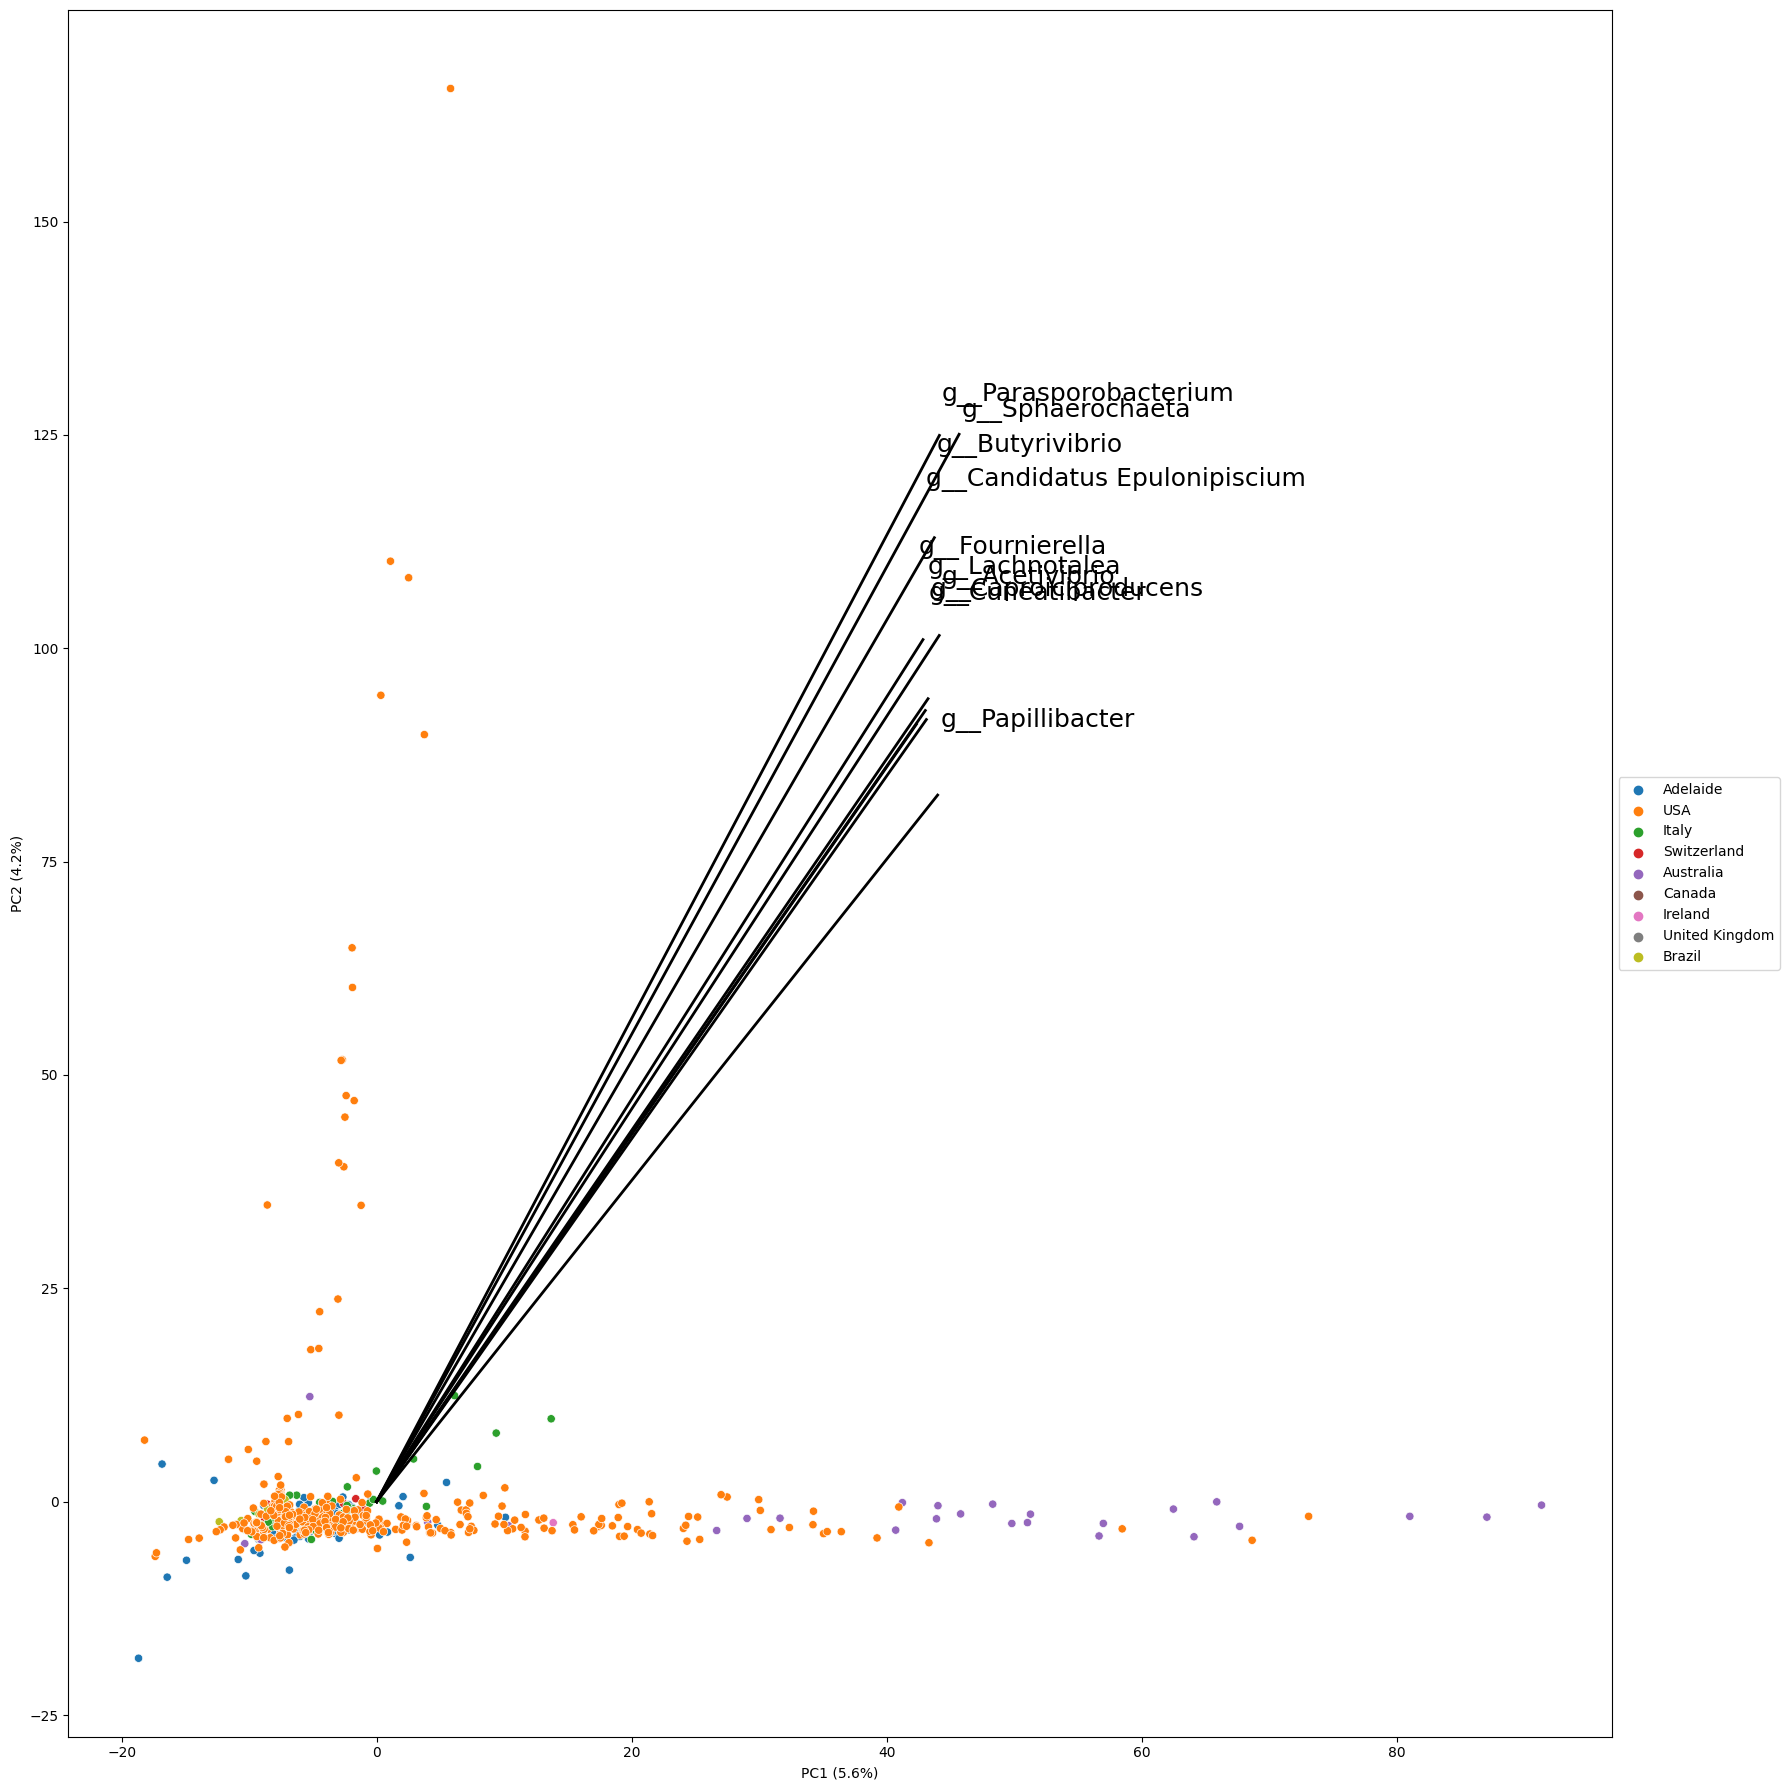

In [35]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC1", y="PC2", hue='Country', legend=True, data=pcloc, ax=ax)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
l = ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
l = ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
# get the 5 largest loadings
ldf = loadings.loc[loadings.abs().nlargest(10, ['PC1', 'PC2']).index]
# get the maximum values for x and y for the loadings and the PCA
mlx = max(ldf.PC1)
mly = max(ldf.PC2)
mpx = max(pct_df.PC1)
mpy = max(pct_df.PC2)

c = 0
for i, l in ldf.iterrows():
    c+=2
    # scale the loadings to fit the figure
    ex = ( l.PC1 * (mpx/mlx) ) / 2
    ey = ( l.PC2 * (mpy/mly) ) / 2
    # add the text and the line
    plt.text(ex+0.2, ey+c, i, fontsize=18)
    plt.plot([0, ex ], [0, ey ], 'k-', lw=2)

plt.tight_layout()

# Phylum Level (without Eukaryotes)

In [36]:
taxon = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\all_taxa.tsv", delimiter="\t")
taxon[taxon['Superkingdom'] == 's__Eukaryota']['Genus']

106809         g__Cafeteria
106810         g__Cafeteria
106811      g__Blastocystis
106812      g__Blastocystis
106813      g__Blastocystis
                ...        
112426         g__Coemansia
112427         g__Linderina
112428     g__Piptocephalis
112429       g__Syncephalis
112430    g__Thamnocephalis
Name: Genus, Length: 5622, dtype: object

### Read the Adelaide data without the Eukaryotes

In [37]:
adl = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\Adelaide\\CF_Taxonomy\\phylum.tsv", delimiter="\t")
adl = adl.rename(columns={"#NAME":"Accession"})
adl = adl.set_index("Accession")
adl = adl[~adl.index.isin(taxon[taxon['Superkingdom'] == 's__Eukaryota']['Phylum'])]
adl = adl.reindex(natsorted(adl.columns), axis=1)
adl = adl.T
# normalise the data by the row sum before we add the label
adl = adl.div(adl.sum(axis=1), axis=0)
adl['geo_loc_name_country_calc'] = "Adelaide"
adl

Accession,p__Candidatus Aerophobetes,p__Candidatus Moranbacteria,p__candidate division WOR-3,p__candidate division LCP-89,p__Candidatus Marsarchaeota,p__Candidatus Harrisonbacteria,p__Aquificae,p__Fusobacteria,p__Candidatus Fraserbacteria,p__Candidatus Fischerbacteria,...,p__Candidatus Nomurabacteria,p__Candidatus Melainabacteria,p__Candidatus Gracilibacteria,p__Candidatus Goldbacteria,p__Thermotogae,p__Candidatus Poribacteria,p__Atribacterota,p__Deferribacteres,p__Candidatus Parvarchaeota,geo_loc_name_country_calc
623361_20180123_S,2.929748e-06,1.464874e-06,8.300951e-06,0.000000,4.882913e-07,0.000000e+00,0.000014,0.034295,0.000000e+00,0.000000e+00,...,3.906330e-06,0.000006,2.441456e-06,0.0,0.000048,0.000004,0.000006,0.000004,0.000000e+00,Adelaide
634207_20180510_S,2.620351e-06,4.526061e-06,2.763279e-05,0.000000,1.191069e-06,2.382137e-07,0.000024,0.049640,0.000000e+00,4.764274e-07,...,9.528549e-07,0.000009,8.337480e-06,0.0,0.000105,0.000005,0.000014,0.000011,2.382137e-07,Adelaide
634207_20180517_S,1.607524e-06,2.411286e-06,2.009405e-05,0.000000,8.037619e-07,0.000000e+00,0.000006,0.011351,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000007,5.224453e-06,0.0,0.000080,0.000003,0.000002,0.000006,0.000000e+00,Adelaide
639354_20171206_S,0.000000e+00,0.000000e+00,2.169244e-06,0.000000,0.000000e+00,0.000000e+00,0.000009,0.017259,0.000000e+00,2.169244e-06,...,2.169244e-06,0.000002,3.687716e-05,0.0,0.000026,0.000000,0.000007,0.000009,0.000000e+00,Adelaide
642660_20180601_S,7.472328e-07,7.472328e-07,0.000000e+00,0.000002,0.000000e+00,7.472328e-07,0.000005,0.003924,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000001,0.000000e+00,0.0,0.000016,0.000001,0.000001,0.000003,0.000000e+00,Adelaide
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1690154_20180406_S,0.000000e+00,4.520348e-07,4.520348e-07,0.000000,4.520348e-07,9.040696e-07,0.000004,0.003243,0.000000e+00,0.000000e+00,...,1.356104e-06,0.000001,1.808139e-06,0.0,0.000019,0.000001,0.000004,0.000004,0.000000e+00,Adelaide
1723809_20180227_S,2.051949e-06,4.983306e-06,4.690170e-06,0.000000,0.000000e+00,0.000000e+00,0.000010,0.033495,2.931356e-07,2.931356e-07,...,4.397035e-06,0.000006,4.103899e-06,0.0,0.000052,0.000013,0.000007,0.000008,2.931356e-07,Adelaide
1834617_20180501_S,0.000000e+00,1.314723e-06,2.191205e-06,0.000000,1.314723e-06,0.000000e+00,0.000007,0.002067,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000002,8.764822e-07,0.0,0.000014,0.000006,0.000005,0.000004,0.000000e+00,Adelaide
1845116_20180403_S,2.082969e-06,7.030020e-06,1.067522e-05,0.000000,2.603711e-06,1.041484e-06,0.000016,0.030670,0.000000e+00,1.041484e-06,...,1.822598e-06,0.000010,4.270086e-04,0.0,0.000065,0.000004,0.000008,0.000012,0.000000e+00,Adelaide


### Read the Worldwide data without the Eukaryotes

In [38]:
wlt = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\mmseqs_taxonomy\\phylum.tsv", delimiter="\t")
wlt = wlt.rename(columns={"#NAME":"Accession"})
wlt = wlt.set_index('Accession')
wlt = wlt.reindex(natsorted(wlt.columns), axis=1)
wlt = wlt[~wlt.index.isin(taxon[taxon['Superkingdom'] == 's__Eukaryota']['Phylum'])]
wlt = wlt.T
# normalise the data by the row sum 
wlt = wlt.div(wlt.sum(axis=1), axis=0)
six = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\16S.tsv", delimiter="\t")
sr = six[six["Aligned 1 time"] > 1]
wlt = wlt[~wlt.index.isin(sr['Run'])]
wlt

Accession,p__Candidatus Altiarchaeota,p__Candidatus Falkowbacteria,p__Abditibacteriota,p__Cressdnaviricota,p__Gemmatimonadetes,p__Candidatus Huberarchaea,p__Candidatus Shapirobacteria,p__Candidatus Berkelbacteria,p__Candidatus Aerophobetes,p__Candidatus Cloacimonetes,...,p__Candidatus Riflebacteria,p__Candidatus Doudnabacteria,p__Candidatus Korarchaeota,p__Candidatus Firestonebacteria,p__Candidatus Heimdallarchaeota,p__Actinomycetota,p__Candidatus Thermoplasmatota,p__Candidatus Calescamantes,p__Thaumarchaeota,p__Candidatus Poribacteria
SRR1177122,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000005,0.0,0.000000e+00,4.530052e-06,0.000000e+00,0.000005,...,9.060105e-06,0.000000e+00,2.265026e-05,0.000000e+00,9.060105e-06,0.064100,0.000009,0.000000e+00,0.000041,0.000000
SRR1180012,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000007,0.0,0.000000e+00,7.007512e-06,0.000000e+00,0.000014,...,0.000000e+00,0.000000e+00,1.051127e-05,0.000000e+00,2.102254e-05,0.102818,0.000004,0.000000e+00,0.000018,0.000000
SRR1180013,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000034,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000034,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.714296e-05,0.062486,0.000017,0.000000e+00,0.000223,0.000000
SRR3284698,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000034,0.0,0.000000e+00,0.000000e+00,4.030105e-06,0.000004,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.045157e-06,0.032456,0.000149,0.000000e+00,0.017593,0.000002
SRR3284701,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000030,0.0,0.000000e+00,2.742634e-06,0.000000e+00,0.000000,...,2.742634e-06,0.000000e+00,0.000000e+00,0.000000e+00,2.742634e-06,0.041331,0.000208,0.000000e+00,0.022797,0.000008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,4.930587e-07,7.748065e-07,1.408739e-07,0.000000e+00,0.000029,0.0,2.113109e-07,2.042672e-06,3.240100e-06,0.000016,...,3.028789e-06,3.240100e-06,3.733159e-06,1.408739e-07,6.832385e-06,0.285343,0.000059,0.000000e+00,0.000007,0.000010
SRR24155134,2.289886e-06,1.253985e-06,0.000000e+00,0.000000e+00,0.000018,0.0,5.452110e-08,1.799196e-06,2.726055e-06,0.000011,...,2.726055e-06,0.000000e+00,1.962760e-06,7.632954e-07,2.398928e-06,0.373588,0.000061,0.000000e+00,0.000010,0.000010
SRR24155135,3.571379e-07,1.339267e-07,4.464224e-08,0.000000e+00,0.000005,0.0,0.000000e+00,1.473194e-06,4.017802e-07,0.000002,...,4.910647e-07,3.571379e-07,3.124957e-07,8.928449e-08,5.803492e-07,0.891462,0.000038,0.000000e+00,0.000003,0.000002
SRR24155136,0.000000e+00,4.893263e-07,2.796150e-07,6.990376e-08,0.000005,0.0,1.048556e-06,4.893263e-07,4.893263e-07,0.000006,...,2.097113e-07,1.398075e-07,2.726246e-06,2.097113e-07,4.893263e-07,0.523119,0.000042,0.000000e+00,0.000003,0.000003


In [39]:
wmd = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\bq-results-20230813-093918-1691921491006.tsv", delimiter="\t")
wma = wmd[['Accession', 'geo_loc_name_country_calc']]
wma = wma.set_index("Accession")
wldj = wlt.join(wma,  how='inner')
comb = pd.concat([adl, wldj], axis=0)
locs = comb[['geo_loc_name_country_calc']]
locs = locs.rename(columns={"geo_loc_name_country_calc": "Country"})
df = comb.drop(['geo_loc_name_country_calc'], axis=1)
df = df.dropna(axis=1)
df

,p__Candidatus Aerophobetes,p__Candidatus Moranbacteria,p__candidate division WOR-3,p__candidate division LCP-89,p__Candidatus Marsarchaeota,p__Candidatus Harrisonbacteria,p__Aquificae,p__Fusobacteria,p__Candidatus Fraserbacteria,p__Candidatus Fischerbacteria,...,p__candidate division NC10,p__Candidatus Nomurabacteria,p__Candidatus Melainabacteria,p__Candidatus Gracilibacteria,p__Candidatus Goldbacteria,p__Thermotogae,p__Candidatus Poribacteria,p__Atribacterota,p__Deferribacteres,p__Candidatus Parvarchaeota
623361_20180123_S,2.929748e-06,1.464874e-06,8.300951e-06,0.000000e+00,4.882913e-07,0.000000e+00,0.000014,0.034295,0.000000e+00,0.000000e+00,...,2.441456e-06,3.906330e-06,0.000006,2.441456e-06,0.000000e+00,0.000048,0.000004,0.000006,0.000004,0.000000e+00
634207_20180510_S,2.620351e-06,4.526061e-06,2.763279e-05,0.000000e+00,1.191069e-06,2.382137e-07,0.000024,0.049640,0.000000e+00,4.764274e-07,...,2.620351e-06,9.528549e-07,0.000009,8.337480e-06,0.000000e+00,0.000105,0.000005,0.000014,0.000011,2.382137e-07
634207_20180517_S,1.607524e-06,2.411286e-06,2.009405e-05,0.000000e+00,8.037619e-07,0.000000e+00,0.000006,0.011351,0.000000e+00,0.000000e+00,...,3.616929e-06,0.000000e+00,0.000007,5.224453e-06,0.000000e+00,0.000080,0.000003,0.000002,0.000006,0.000000e+00
639354_20171206_S,0.000000e+00,0.000000e+00,2.169244e-06,0.000000e+00,0.000000e+00,0.000000e+00,0.000009,0.017259,0.000000e+00,2.169244e-06,...,0.000000e+00,2.169244e-06,0.000002,3.687716e-05,0.000000e+00,0.000026,0.000000,0.000007,0.000009,0.000000e+00
642660_20180601_S,7.472328e-07,7.472328e-07,0.000000e+00,2.241698e-06,0.000000e+00,7.472328e-07,0.000005,0.003924,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000001,0.000000e+00,0.000000e+00,0.000016,0.000001,0.000001,0.000003,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR24155132,3.240100e-06,1.056554e-05,7.325443e-06,0.000000e+00,2.817478e-07,0.000000e+00,0.000011,0.000319,0.000000e+00,2.113109e-07,...,1.690487e-06,8.452435e-07,0.000030,1.197428e-06,2.113109e-07,0.000040,0.000010,0.000013,0.000015,0.000000e+00
SRR24155134,2.726055e-06,6.051842e-06,1.690154e-06,5.452110e-08,6.542532e-07,3.271266e-07,0.000009,0.000330,1.090422e-07,9.813798e-07,...,6.815137e-06,1.308506e-06,0.000007,3.434829e-06,2.180844e-07,0.000045,0.000010,0.000010,0.000009,1.090422e-07
SRR24155135,4.017802e-07,6.964190e-06,1.339267e-06,0.000000e+00,4.464224e-08,1.044628e-05,0.000002,0.000085,4.464224e-08,4.464224e-08,...,9.821294e-07,8.482026e-07,0.000004,2.232112e-07,0.000000e+00,0.000053,0.000002,0.000001,0.000002,0.000000e+00
SRR24155136,4.893263e-07,1.817498e-06,6.990376e-07,6.990376e-08,9.786526e-07,9.087488e-07,0.000013,0.000290,0.000000e+00,2.097113e-07,...,2.097113e-07,6.990376e-08,0.000010,9.786526e-07,0.000000e+00,0.000014,0.000003,0.000004,0.000007,0.000000e+00


In [40]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
pca = PCA(n_components=4)
pca.fit(df_scaled)
dft_pca = pca.transform(df_scaled)
zipped = list(zip(dft_pca[:,0],
                  dft_pca[:,1],
                  dft_pca[:,2],
                  dft_pca[:,3],
                  list(df.index),
                 ))
pct_df = pd.DataFrame(zipped, columns=['PC1', 'PC2', 'PC3', 'PC4', "Accession"])
pcloc = pct_df.set_index("Accession").join(locs, how="inner")
pcloc = pcloc[pcloc['Country'] != 'uncalculated']
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2', 'PC3', 'PC4'], index=df.columns)
loadings.head(3)

,PC1,PC2,PC3,PC4
p__Candidatus Aerophobetes,0.078660,0.024871,-0.066607,-0.054100
p__Candidatus Moranbacteria,0.120630,-0.042637,-0.011593,0.035588
p__candidate division WOR-3,0.144431,-0.042511,-0.075947,-0.018024


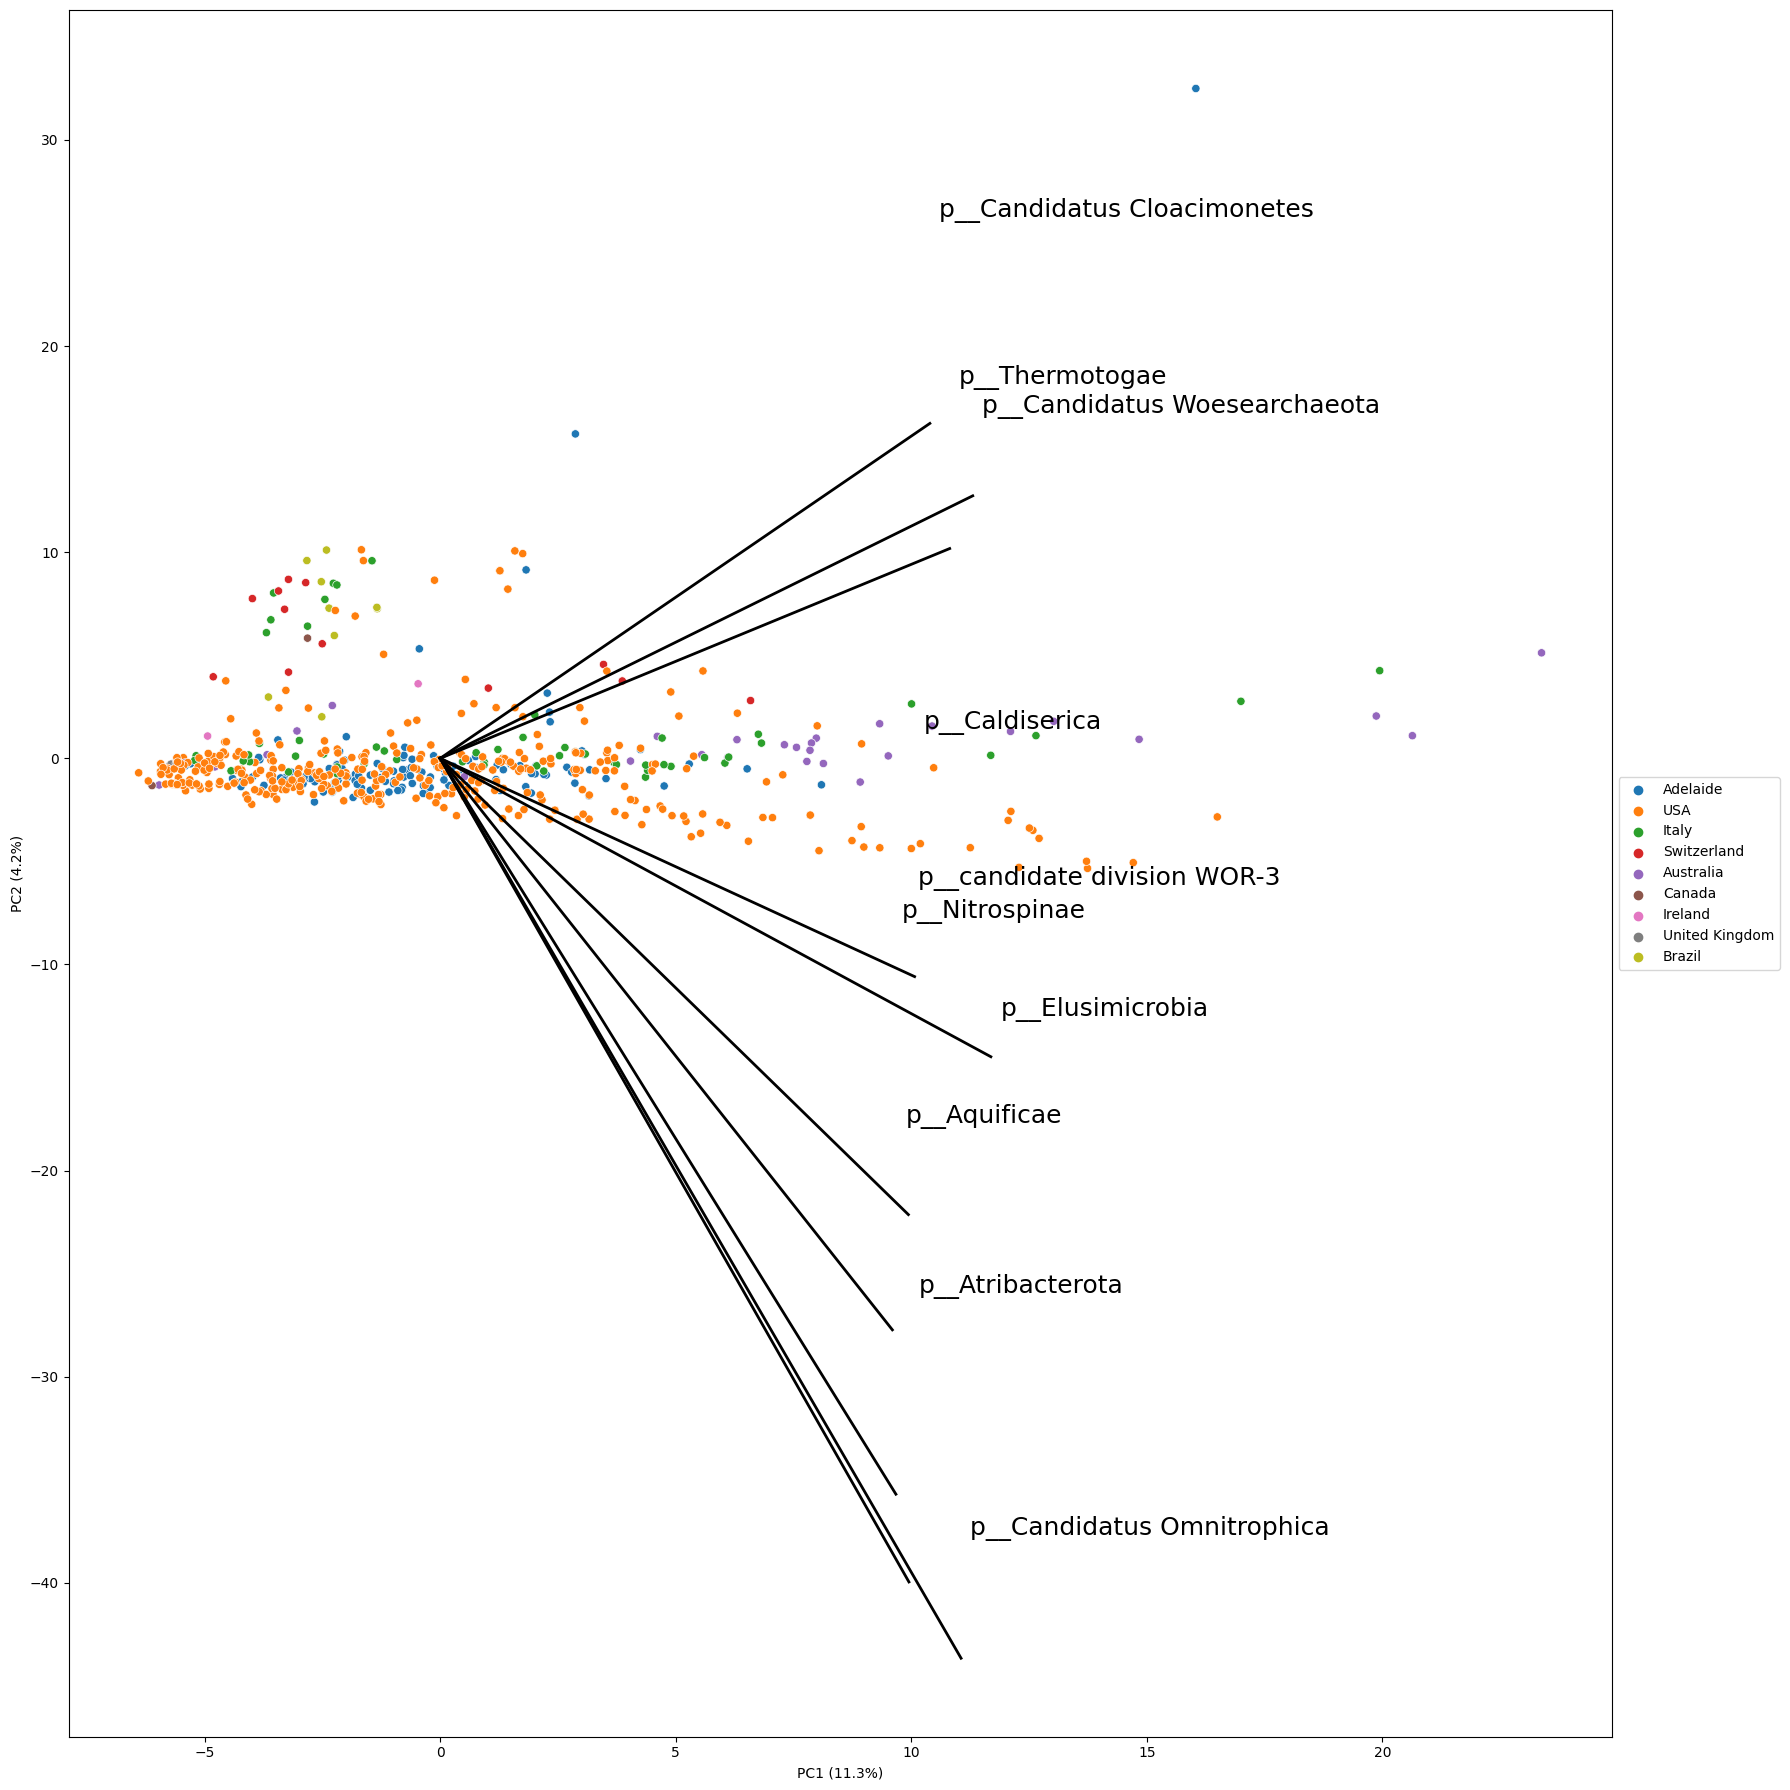

In [41]:
fig, ax = plt.subplots(figsize=(18, 18))
sns.scatterplot(x="PC1", y="PC2", hue='Country', legend=True, data=pcloc, ax=ax)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
l = ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
l = ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
# get the 5 largest loadings
ldf = loadings.loc[loadings.abs().nlargest(10, ['PC1', 'PC2']).index]
# get the maximum values for x and y for the loadings and the PCA
mlx = max(ldf.PC1)
mly = max(ldf.PC2)
mpx = max(pct_df.PC1)
mpy = max(pct_df.PC2)

c = 0
for i, l in ldf.iterrows():
    c+=2
    # scale the loadings to fit the figure
    ex = ( l.PC1 * (mpx/mlx) ) / 2
    ey = ( l.PC2 * (mpy/mly) ) / 2
    # add the text and the line
    plt.text(ex+0.2, ey+c, i, fontsize=18)
    plt.plot([0, ex ], [0, ey ], 'k-', lw=2)

plt.tight_layout()
fig.savefig("Worldwide_phylum.png")

In [56]:
df['p__Candidatus Cloacimonetes'].sort_values()

1162967_20180116_S     0.000000
SRR3284701             0.000000
SRR19051567            0.000000
SRR19051570            0.000000
SRR19051586            0.000000
                         ...   
650003_20180213_S      0.000073
SRR8482173             0.000075
SRR11440773            0.000075
SRR8482117             0.000076
768745_20190228_BAL    0.000273
Name: p__Candidatus Cloacimonetes, Length: 611, dtype: float64

In [58]:
df.loc['768745_20190228_S', 'p__Candidatus Cloacimonetes']

1.5150425752642336e-05

In [59]:
df.loc['768745_20190228_BAL', 'p__Candidatus Cloacimonetes']

0.0002725538293813028

# MASH Distances

I calculated all pairwise mash distances. Distances are for the R1 and R2 reads.

In [42]:
msh = pd.read_csv("C:\\Users\\edwa0468\\OneDrive - Flinders\\Projects\\CF\\OtherSequences\\pairwise_mash_distances.no16s.tsv.gz", compression='gzip', delimiter="\t")
msh

,From,To,Distance,p-value,kmers
0,SRR10267760,SRR10267760,0.000000,0.000000e+00,1000/1000
1,SRR10267761,SRR10267760,0.122140,9.205380e-140,40/1000
2,SRR10267762,SRR10267760,0.098138,9.371560e-257,68/1000
3,SRR10267763,SRR10267760,0.109331,2.501330e-204,53/1000
4,SRR10267765,SRR10267760,0.128270,2.206470e-136,35/1000
...,...,...,...,...,...
736159,895293_20180502_S,983493_20180123_S,0.098138,4.563390e-237,68/1000
736160,896213_20180427_S,983493_20180123_S,0.154223,9.761470e-69,20/1000
736161,913873_20180417_S,983493_20180123_S,0.178173,6.960310e-42,12/1000
736162,980574_20180403_S,983493_20180123_S,0.111073,7.693610e-173,51/1000


In [43]:
mshp = pd.pivot(msh, index="From", columns="To", values='Distance')
mshp

To,1068841_20180306_S,1112926_20171212_S,1128691_20171206_S,1128691_20171218_S,1128691_20180116_S,1162967_20180116_S,1255498_20171212_S,1282052_20180206_S,1316935_20180417_S,1316979_20171215_S,...,SRR8482183,SRR8482185,SRR8482186,SRR8482187,SRR8482188,SRR8482189,SRR8482190,SRR9701179,SRR9701183,SRR9701189
From,,,,,,,,,,,,,,,,,,,,,
1068841_20180306_S,0.000000,0.077463,0.167688,0.161822,0.219531,0.149777,0.088783,0.113823,0.088264,0.094378,...,0.186761,0.219531,0.219531,0.129604,0.156619,0.112887,0.114780,0.263022,1.000000,0.263022
1112926_20171212_S,0.077463,0.000000,0.111073,0.114780,0.133864,0.104495,0.081179,0.072306,0.083404,0.088264,...,0.125715,0.132399,0.142009,0.099470,0.111073,0.096846,0.092618,0.230110,0.295981,0.230110
1128691_20171206_S,0.167688,0.111073,0.000000,0.051920,0.051725,0.063168,0.136948,0.106047,0.130979,0.164662,...,0.055428,0.055865,0.061843,0.075541,0.062632,0.108487,0.102997,0.295981,1.000000,1.000000
1128691_20171218_S,0.161822,0.114780,0.051920,0.000000,0.054997,0.066265,0.135380,0.100846,0.125715,0.143830,...,0.057440,0.056983,0.059574,0.079484,0.065394,0.107658,0.102997,0.263022,1.000000,1.000000
1128691_20180116_S,0.219531,0.133864,0.051725,0.054997,0.000000,0.063987,0.219531,0.115759,0.138572,0.210897,...,0.052117,0.047344,0.050200,0.074070,0.062104,0.108487,0.102268,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR8482189,0.112887,0.096846,0.108487,0.107658,0.108487,0.098798,0.110193,0.098798,0.093196,0.111970,...,0.094378,0.100152,0.102997,0.053733,0.083864,0.000000,0.035042,0.263022,0.295981,0.263022
SRR8482190,0.114780,0.092618,0.102997,0.102997,0.102268,0.096846,0.115759,0.100152,0.096846,0.115759,...,0.092048,0.096215,0.107658,0.050764,0.080748,0.035042,0.000000,0.295981,1.000000,1.000000
SRR9701179,0.263022,0.230110,0.295981,0.263022,1.000000,0.295981,0.243761,0.243761,0.295981,0.295981,...,1.000000,1.000000,1.000000,0.263022,0.263022,0.263022,0.295981,0.000000,0.154223,0.138572


c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method

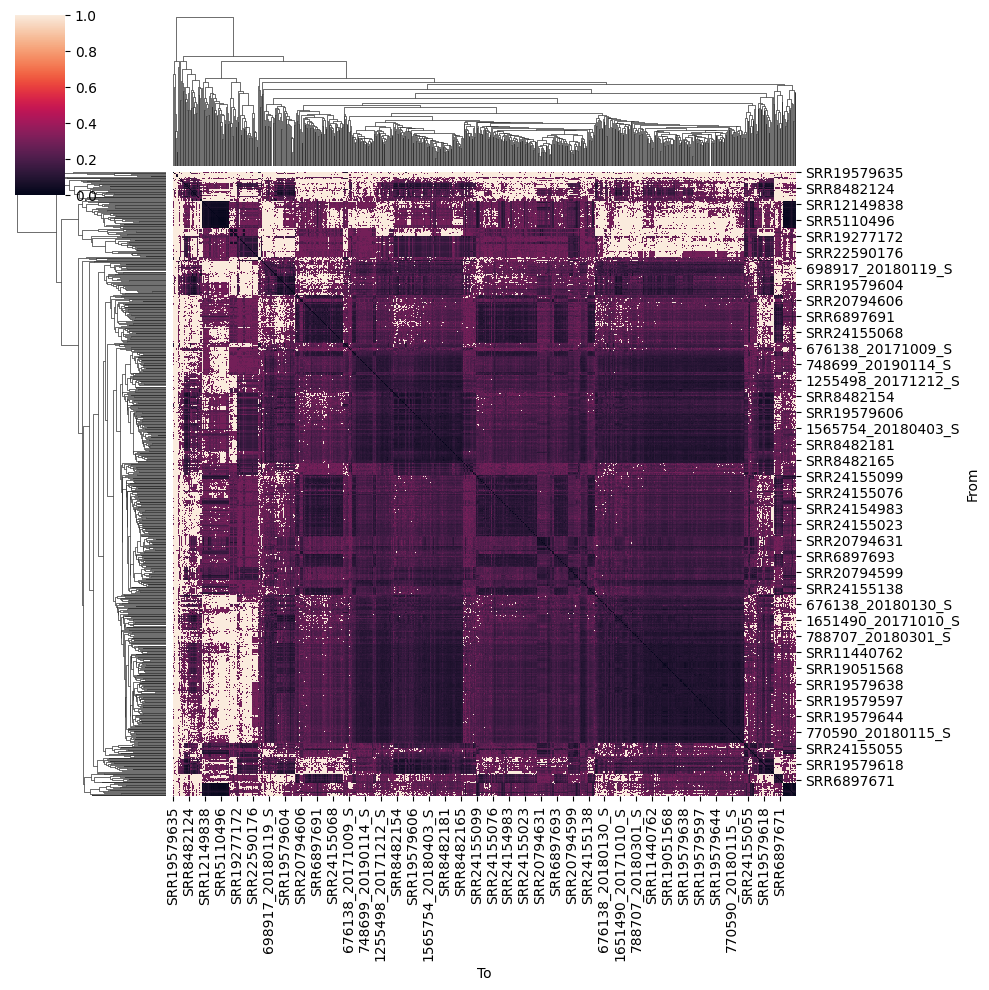

In [44]:
sns.clustermap(mshp)

In [45]:
locs

,Country
623361_20180123_S,Adelaide
634207_20180510_S,Adelaide
634207_20180517_S,Adelaide
639354_20171206_S,Adelaide
642660_20180601_S,Adelaide
...,...
SRR24155132,USA
SRR24155134,USA
SRR24155135,USA
SRR24155136,USA


In [46]:
msf = msh.join(locs, on="From", how="inner")
msf = msf.rename(columns={"Country": "From Country"})
mst = msf.join(locs, on="To", how="inner")
mst = mst.rename(columns={"Country": "To Country"})
mst

,From,To,Distance,p-value,kmers,From Country,To Country
14603,SRR10590818,SRR10590818,0.000000,0.000000e+00,1000/1000,Canada,Canada
14604,SRR11361785,SRR10590818,0.243761,1.534620e-05,3/1000,United Kingdom,Canada
14606,SRR11361787,SRR10590818,0.243761,1.053230e-05,3/1000,United Kingdom,Canada
14608,SRR11361790,SRR10590818,0.243761,1.386180e-05,3/1000,United Kingdom,Canada
14611,SRR11361794,SRR10590818,0.243761,8.050930e-06,3/1000,United Kingdom,Canada
...,...,...,...,...,...,...,...
736159,895293_20180502_S,983493_20180123_S,0.098138,4.563390e-237,68/1000,Adelaide,Adelaide
736160,896213_20180427_S,983493_20180123_S,0.154223,9.761470e-69,20/1000,Adelaide,Adelaide
736161,913873_20180417_S,983493_20180123_S,0.178173,6.960310e-42,12/1000,Adelaide,Adelaide
736162,980574_20180403_S,983493_20180123_S,0.111073,7.693610e-173,51/1000,Adelaide,Adelaide


In [47]:
mstp = mst.pivot(index="From", columns="To", values="Distance")
mstp

To,1068841_20180306_S,1112926_20171212_S,1128691_20171206_S,1128691_20171218_S,1128691_20180116_S,1162967_20180116_S,1255498_20171212_S,1282052_20180206_S,1316935_20180417_S,1316979_20171215_S,...,SRR8482177,SRR8482178,SRR8482179,SRR8482180,SRR8482181,SRR8482183,SRR8482185,SRR8482187,SRR8482190,SRR9701183
From,,,,,,,,,,,,,,,,,,,,,
1068841_20180306_S,0.000000,0.077463,0.167688,0.161822,0.219531,0.149777,0.088783,0.113823,0.088264,0.094378,...,0.178173,0.151946,0.112887,0.076683,0.097487,0.186761,0.219531,0.129604,0.114780,1.000000
1112926_20171212_S,0.077463,0.000000,0.111073,0.114780,0.133864,0.104495,0.081179,0.072306,0.083404,0.088264,...,0.145727,0.106845,0.087751,0.079901,0.077463,0.125715,0.132399,0.099470,0.092618,0.295981
1128691_20171206_S,0.167688,0.111073,0.000000,0.051920,0.051725,0.063168,0.136948,0.106047,0.130979,0.164662,...,0.156619,0.068691,0.072306,0.140258,0.079071,0.055428,0.055865,0.075541,0.102997,1.000000
1128691_20171218_S,0.161822,0.114780,0.051920,0.000000,0.054997,0.066265,0.135380,0.100846,0.125715,0.143830,...,0.147707,0.073002,0.074432,0.133864,0.079901,0.057440,0.056983,0.079484,0.102997,1.000000
1128691_20180116_S,0.219531,0.133864,0.051725,0.054997,0.000000,0.063987,0.219531,0.115759,0.138572,0.210897,...,0.154223,0.066560,0.076683,0.154223,0.078259,0.052117,0.047344,0.074070,0.102268,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR8482183,0.186761,0.125715,0.055428,0.057440,0.052117,0.059330,0.164662,0.110193,0.130979,0.191731,...,0.124491,0.056983,0.060315,0.122140,0.071963,0.000000,0.034360,0.069006,0.092048,1.000000
SRR8482185,0.219531,0.132399,0.055865,0.056983,0.047344,0.059330,0.243761,0.115759,0.142009,0.243761,...,0.114780,0.058137,0.068070,0.151946,0.080748,0.034360,0.000000,0.071623,0.096215,1.000000
SRR8482187,0.129604,0.099470,0.075541,0.079484,0.074070,0.074070,0.135380,0.101551,0.114780,0.138572,...,0.106845,0.071623,0.069006,0.100152,0.067458,0.069006,0.071623,0.000000,0.050764,1.000000


In [48]:
mst['From Country'].unique()

array(['Canada', 'United Kingdom', 'USA', 'Brazil', 'Australia', 'Italy',
       'Switzerland', 'Ireland', 'Adelaide'], dtype=object)

In [49]:
lut = dict(zip(mst['From Country'].unique(), sns.color_palette()))
rc = mst['From Country'].map(lut)
cc = mst['To Country'].map(lut)

In [50]:
lut = dict(zip(mst['From Country'].unique(), sns.color_palette()))
rc = locs.loc[mstp.index]['Country'].map(lut)
cc = locs.loc[mstp.columns]['Country'].map(lut)

c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method

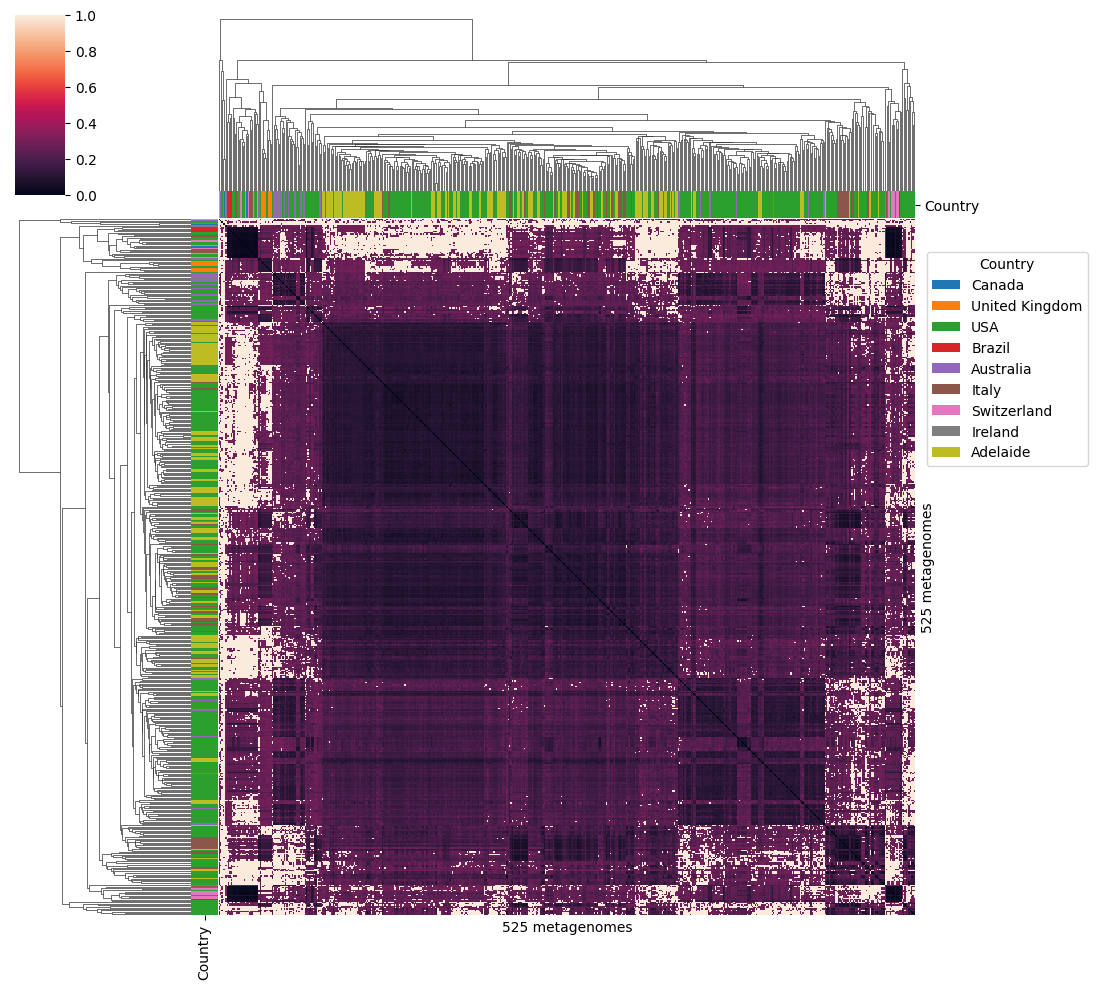

In [51]:
cg = sns.clustermap(mstp,
                   row_cluster=True, col_cluster=True, 
                   row_colors=rc, col_colors=cc,
                   yticklabels=False,xticklabels=False)
ax = cg.ax_heatmap
ax.set_ylabel("525 metagenomes")
ax.set_xlabel("525 metagenomes")
handles = [Patch(facecolor=lut[name]) for name in lut]
l = plt.legend(handles, lut, title='Country',
           bbox_to_anchor=(1.1, 0.75), bbox_transform=plt.gcf().transFigure, loc='upper right')

plt.tight_layout()
cg.savefig("mash_distances.png")

c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\workspace\edwa0468\githubs\edwardslab\venv_win\lib\site-packages\seaborn\matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method

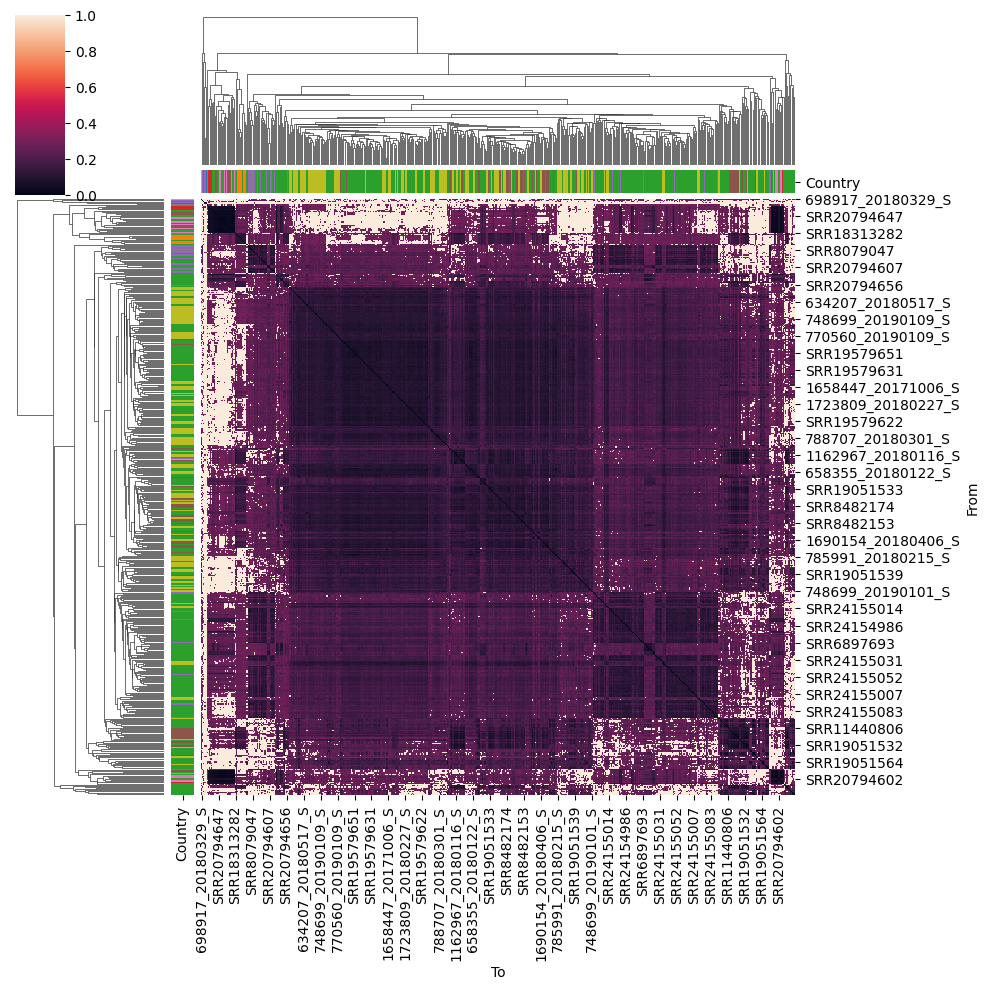

In [52]:
g = sns.clustermap(mstp, 
               row_cluster=True, col_cluster=True, 
               row_colors=rc, col_colors=cc)